In [13]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="API")
project = rf.workspace("panopticindoor").project("panoptic-indoor-segmentation")
version = project.version(5)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to panoptic-indoor-segmentation-5 in yolov8:: 100%|██████████| 1856/1856 [00:00<00:00, 3300.31it/s]


In [26]:
!pip install -q ultralytics

In [4]:
import os
import cv2
import yaml
import time
import torch
import random
import numpy as np
from ultralytics import YOLO
import matplotlib.pyplot as plt


print("Lokasi dataset:", dataset.location)
print("Isi folder:", os.listdir(dataset.location))


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Lokasi dataset: /content/panoptic-indoor-segmentation-5
Isi folder: ['valid', 'train', 'README.dataset.txt', 'README.roboflow.txt', 'test', 'data.yaml']


In [13]:
dataset_path = dataset.location

for split in ["train", "valid", "test"]:
    image_dir = os.path.join(dataset_path, split, "images")
    label_dir = os.path.join(dataset_path, split, "labels")

    images = [f for f in os.listdir(image_dir)
              if f.lower().endswith((".jpg", ".jpeg", ".png"))]

    labels = [f for f in os.listdir(label_dir)
              if f.endswith(".txt")]

    print(f"{split.upper()}")
    print(f"  Jumlah gambar : {len(images)}")
    print(f"  Jumlah label  : {len(labels)}")
    print()

TRAIN
  Jumlah gambar : 397
  Jumlah label  : 397

VALID
  Jumlah gambar : 166
  Jumlah label  : 166

TEST
  Jumlah gambar : 359
  Jumlah label  : 359



In [ ]:
with open(os.path.join(dataset_path, "data.yaml"), "r") as f:
    data_config = yaml.safe_load(f)

print("Konfigurasi dataset:")
print(data_config)

print("\nDaftar kelas objek:")
for i, name in enumerate(data_config["names"]):
    print(f"{i}: {name}")

Konfigurasi dataset:
{'names': ['backpack', 'bed', 'blanket', 'book', 'bottle', 'bowl', 'box', 'cabinet-merged', 'cardboard', 'ceiling-merged', 'cell phone', 'chair', 'clock', 'couch', 'counter', 'cup', 'curtain', 'dining table', 'door-stuff', 'fire-extinguisher', 'floor-other-merged', 'floor-wood', 'flower', 'food-other-merged', 'fork', 'hair drier', 'handbag', 'keyboard', 'knife', 'laptop', 'light', 'microwave', 'mirror-stuff', 'mouse', 'oven', 'pan', 'paper', 'paper-merged', 'person', 'pillow', 'plate', 'plug', 'potted plant', 'refrigerator', 'remote', 'rug-merged', 'scissor', 'scissors', 'shelf', 'sink', 'spoon', 'st-', 'stairs', 'stove-merged', 'table-merged', 'teddy bear', 'toaster', 'toilet', 'toothbrush', 'towel', 'toy', 'trash-bin', 'tree-merged', 'tv', 'vase', 'wall', 'wall-brick', 'wall-other-merged', 'wall-stone', 'wall-tile', 'wall-wood', 'wallet', 'window-blind', 'window-other'], 'nc': 74, 'roboflow': {'license': 'CC BY 4.0', 'project': 'panoptic-indoor-segmentation', 'ur

In [ ]:
label_dir = os.path.join(dataset_path, "train", "labels")

label_files = [
    f for f in os.listdir(label_dir)
    if f.endswith(".txt") and os.path.getsize(
        os.path.join(label_dir, f)
    ) > 0
]

if label_files:
    label_path = os.path.join(label_dir, label_files[0])

    with open(label_path, "r") as f:
        lines = f.readlines()

    print("Contoh file anotasi:", label_files[0])
    print("Jumlah objek:", len(lines))

    if lines:
        values = lines[0].strip().split()
        print("Class ID:", values[0])
        print("Jumlah koordinat:", len(values) - 1)
        print("Contoh isi:", " ".join(values[:11]), "...")
else:
    print("Tidak ditemukan file anotasi yang berisi objek.")


Contoh file anotasi: 182169208_jpg.rf.ab76d2866e67e77a64e87ac2340cf4bb.txt
Jumlah objek: 2
Class ID: 54
Jumlah koordinat: 98
Contoh isi: 54 1 0.9934895833333334 0.9990234375 0.005208333333333333 0.7373046875 0.005208333333333333 0.74609375 0.032552083333333336 0.75 0.07942708333333333 ...


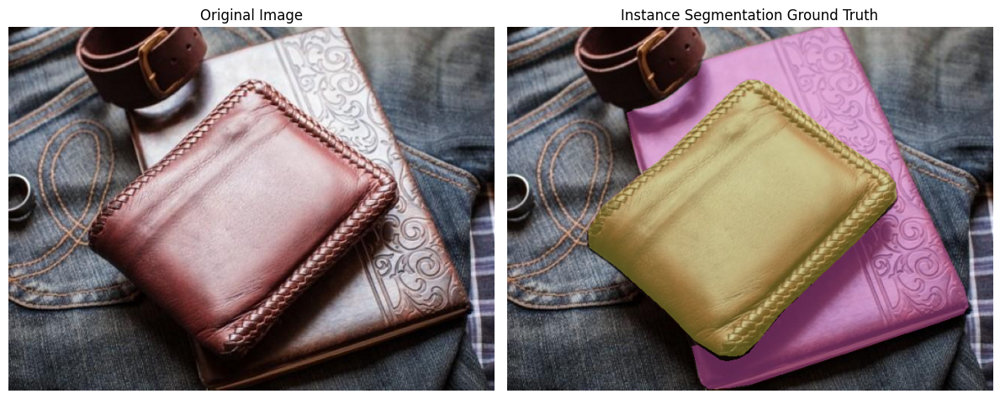

Nama gambar: 182169300_jpg.rf.160d9d83354ddd838342d0da91cb8426.jpg


In [ ]:
image_dir = os.path.join(dataset.location, "train", "images")
label_dir = os.path.join(dataset.location, "train", "labels")

image_files = [
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Ambil satu gambar secara acak
image_file = random.choice(image_files)

image_path = os.path.join(image_dir, image_file)
label_path = os.path.join(
    label_dir, os.path.splitext(image_file)[0] + ".txt"
)

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

height, width = image.shape[:2]
overlay = image.copy()

# Baca anotasi polygon
if os.path.exists(label_path):
    with open(label_path, "r") as f:
        lines = f.readlines()

    for line in lines:
        values = list(map(float, line.strip().split()))
        class_id = int(values[0])

        coords = np.array(values[1:]).reshape(-1, 2)
        coords[:, 0] *= width
        coords[:, 1] *= height

        polygon = coords.astype(np.int32)

        color = tuple(
            int(x) for x in np.random.randint(0, 256, 3)
        )

        cv2.fillPoly(overlay, [polygon], color)

# Gabungkan gambar dengan mask
result = cv2.addWeighted(image, 0.55, overlay, 0.45, 0)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result)
plt.title("Instance Segmentation Ground Truth")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Nama gambar:", image_file)

In [ ]:
print("CUDA tersedia:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Nama GPU:", torch.cuda.get_device_name(0))
    print("Memori GPU:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    print("GPU belum aktif")


CUDA tersedia: True
Nama GPU: Tesla T4
Memori GPU: 14.56 GB


In [15]:
dataset_path = dataset.location

# Baca konfigurasi dataset asli
with open(os.path.join(dataset_path, "data.yaml"), "r") as f:
    config = yaml.safe_load(f)

# Gunakan path absolut agar Colab bisa menemukan gambar
config["train"] = os.path.join(dataset_path, "train/images")
config["val"] = os.path.join(dataset_path, "valid/images")
config["test"] = os.path.join(dataset_path, "test/images")

# Simpan konfigurasi baru
config_path = os.path.join(dataset_path, "data_colab.yaml")

with open(config_path, "w") as f:
    yaml.safe_dump(config, f)

print("Konfigurasi berhasil disimpan:", config_path)
print("Jumlah kelas:", config["nc"])

Konfigurasi berhasil disimpan: /content/panoptic-indoor-segmentation-5/data_colab.yaml
Jumlah kelas: 74


## 1. YOLO11n-seg

### input 320 x 320

In [ ]:
from ultralytics import YOLO
import time

# Gunakan model YOLO11 Nano untuk segmentation
model = YOLO("yolo11n-seg.pt")

start_time = time.time()

# Training dengan ukuran input 320
results = model.train(
    data=config_path,
    epochs=30,
    imgsz=320,
    batch=8,
    device=0,
    seed=42,
    project="/content/drive/MyDrive/CPMK3/results",
    name="YOLO11n_320",
    exist_ok=True,
    save=True,
    plots=True
)

duration = (time.time() - start_time) / 60

print(f"Waktu training: {duration:.2f} menit")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/panoptic-indoor-segmentation-5/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=tor

### input 640

In [ ]:
from ultralytics import YOLO
import time

# Mulai kembali dari pretrained model yang sama
model_640 = YOLO("yolo11n-seg.pt")

start_time = time.time()

results_640 = model_640.train(
    data=config_path,
    epochs=30,
    imgsz=640,
    batch=8,
    device=0,
    seed=42,
    project="/content/drive/MyDrive/CPMK3/results",
    name="YOLO11n_640",
    exist_ok=True,
    save=True,
    plots=True
)

duration_640 = (time.time() - start_time) / 60

print(f"Waktu training 640: {duration_640:.2f} menit")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/panoptic-indoor-segmentation-5/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=tor

### input 960 x 960

In [ ]:
model_960 = YOLO("yolo11n-seg.pt")

start_time = time.time()

results_960 = model_960.train(
    data=config_path,
    epochs=30,
    imgsz=960,
    batch=8,
    device=0,
    seed=42,
    project="/content/drive/MyDrive/CPMK3/results",
    name="YOLO11n_960",
    exist_ok=True,
    save=True,
    plots=True
)

duration_960 = (time.time() - start_time) / 60

print(f"Waktu training 960: {duration_960:.2f} menit")


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/panoptic-indoor-segmentation-5/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLO11n_960, nbs=64, nms=None,

## 2. YOLOv8n-seg

### input 320

In [ ]:

from ultralytics import YOLO
import time

model_v8_320 = YOLO("yolov8n-seg.pt")

start_time = time.time()

results_v8_320 = model_v8_320.train(
    data=config_path,
    epochs=30,
    imgsz=320,
    batch=8,
    device=0,
    seed=42,
    project="/content/drive/MyDrive/CPMK3/results",
    name="YOLOv8n_320",
    exist_ok=True,
    save=True,
    plots=True
)

duration_v8_320 = (time.time() - start_time) / 60

print(f"Waktu training: {duration_v8_320:.2f} menit")


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/panoptic-indoor-segmentation-5/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv8n_320, nbs=64, nms=None,

### input 640

In [ ]:
model_v8_640 = YOLO("yolov8n-seg.pt")

start_time = time.time()

results_v8_640 = model_v8_640.train(
    data=config_path,
    epochs=30,
    imgsz=640,
    batch=8,
    device=0,
    seed=42,
    project="/content/drive/MyDrive/CPMK3/results",
    name="YOLOv8n_640",
    exist_ok=True,
    save=True,
    plots=True
)

duration_v8_640 = (time.time() - start_time) / 60

print(f"Waktu training: {duration_v8_640:.2f} menit")


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/panoptic-indoor-segmentation-5/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv8n_640, nbs=64, nms=None,

### input 960

In [ ]:
model_v8_960 = YOLO("yolov8n-seg.pt")

start_time = time.time()

results_v8_960 = model_v8_960.train(
    data=config_path,
    epochs=30,
    imgsz=960,
    batch=8,
    device=0,
    seed=42,
    project="/content/drive/MyDrive/CPMK3/results",
    name="YOLOv8n_960",
    exist_ok=True,
    save=True,
    plots=True
)

duration_v8_960 = (time.time() - start_time) / 60

print(f"Waktu training: {duration_v8_960:.2f} menit")


Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/panoptic-indoor-segmentation-5/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv8n_960, nbs=64, nms=None,

## 3. Mask R-CNN

In [15]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="API")
project = rf.workspace("panopticindoor").project("panoptic-indoor-segmentation")
version = project.version(5)
dataset = version.download("coco-segmentation")

dataset_coco = version.download(
    "coco-segmentation",
    location="/content/panoptic-indoor-coco"
)

print("Lokasi dataset COCO:")
print(dataset_coco.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/panoptic-indoor-coco in coco-segmentation:: 100%|██████████| 930/930 [00:00<00:00, 2551.61it/s]

Lokasi dataset COCO:
/content/panoptic-indoor-coco


In [25]:
import os

coco_path = dataset_coco.location

print("Lokasi dataset:", coco_path)
print("\nIsi folder utama:")
print(os.listdir(coco_path))

for split in ["train", "valid", "test"]:
    folder = os.path.join(coco_path, split)

    print(f"\n{split.upper()}")

    if os.path.exists(folder):
        files = os.listdir(folder)

        images = [
            f for f in files
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png")
            )
        ]

        json_files = [
            f for f in files
            if f.endswith(".json")
        ]

        print("Jumlah gambar:", len(images))
        print("File anotasi:", json_files)
    else:
        print("Folder tidak ditemukan")


Lokasi dataset: /content/panoptic-indoor-coco

Isi folder utama:
['valid', 'train', 'README.dataset.txt', 'README.roboflow.txt', 'test']

TRAIN
Jumlah gambar: 397
File anotasi: ['_annotations.coco.json']

VALID
Jumlah gambar: 166
File anotasi: ['_annotations.coco.json']

TEST
Jumlah gambar: 359
File anotasi: ['_annotations.coco.json']


In [26]:
!pip install -q pycocotools

In [18]:

import os
import torch
import numpy as np

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as F
from pycocotools.coco import COCO

class IndoorCOCODataset(Dataset):
    def __init__(self, root, split, category_mapping=None):
        self.image_dir = os.path.join(root, split)
        annotation_file = os.path.join(
            self.image_dir,
            "_annotations.coco.json"
        )

        self.coco = COCO(annotation_file)
        self.ids = sorted(self.coco.getImgIds())

        category_ids = sorted(self.coco.getCatIds())

        # Background = 0, kelas objek mulai dari 1
        if category_mapping is None:
            self.category_mapping = {
                cat_id: i + 1
                for i, cat_id in enumerate(category_ids)
            }
        else:
            self.category_mapping = category_mapping

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        image_id = self.ids[idx]
        image_info = self.coco.loadImgs(image_id)[0]

        image_path = os.path.join(
            self.image_dir,
            image_info["file_name"]
        )

        image = Image.open(image_path).convert("RGB")
        width, height = image.size

        ann_ids = self.coco.getAnnIds(imgIds=[image_id])
        annotations = self.coco.loadAnns(ann_ids)

        boxes = []
        labels = []
        masks = []
        areas = []
        iscrowd = []

        for ann in annotations:
            if ann["category_id"] not in self.category_mapping:
                continue

            # COCO segmentation -> binary mask
            mask = self.coco.annToMask(ann)

            if mask.sum() == 0:
                continue

            ys, xs = np.where(mask > 0)

            x_min, x_max = xs.min(), xs.max()
            y_min, y_max = ys.min(), ys.max()

            # Bounding box harus memiliki luas positif
            x2 = min(x_max + 1, width)
            y2 = min(y_max + 1, height)

            if x2 <= x_min or y2 <= y_min:
                continue

            boxes.append([x_min, y_min, x2, y2])
            labels.append(
                self.category_mapping[ann["category_id"]]
            )
            masks.append(mask)
            areas.append(float(mask.sum()))
            iscrowd.append(int(ann.get("iscrowd", 0)))

        if len(boxes) > 0:
            boxes = torch.as_tensor(boxes, dtype=torch.float32)
            labels = torch.as_tensor(labels, dtype=torch.int64)
            masks = torch.as_tensor(
                np.stack(masks), dtype=torch.uint8
            )
        else:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
            masks = torch.zeros(
                (0, height, width), dtype=torch.uint8
            )

        target = {
            "boxes": boxes,
            "labels": labels,
            "masks": masks,
            "image_id": torch.tensor(image_id),
            "area": torch.tensor(areas, dtype=torch.float32),
            "iscrowd": torch.tensor(iscrowd, dtype=torch.int64)
        }

        image = F.to_tensor(image)

        return image, target

print("Dataset class berhasil dibuat!")

Dataset class berhasil dibuat!


In [22]:

# Lokasi dataset COCO
coco_path = "/content/panoptic-indoor-coco"

# Buat dataset training
train_dataset = IndoorCOCODataset(
    coco_path,
    "train"
)

# Gunakan pemetaan kelas yang sama untuk semua split
val_dataset = IndoorCOCODataset(
    coco_path,
    "valid",
    category_mapping=train_dataset.category_mapping
)

test_dataset = IndoorCOCODataset(
    coco_path,
    "test",
    category_mapping=train_dataset.category_mapping
)

def collate_fn(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=2,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)

print("Jumlah train:", len(train_dataset))
print("Jumlah valid:", len(val_dataset))
print("Jumlah test :", len(test_dataset))
print(
    "Jumlah kelas objek:",
    len(train_dataset.category_mapping)
)

loading annotations into memory...
Done (t=0.09s)
creating index...
index created!
loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
loading annotations into memory...
Done (t=0.13s)
creating index...
index created!
Jumlah train: 397
Jumlah valid: 166
Jumlah test : 359
Jumlah kelas objek: 75


In [29]:
images, targets = next(iter(train_loader))

print("Jumlah gambar dalam batch:", len(images))
print("Ukuran gambar pertama:", images[0].shape)
print("Bounding boxes:", targets[0]["boxes"].shape)
print("Labels:", targets[0]["labels"].shape)
print("Masks:", targets[0]["masks"].shape)

Jumlah gambar dalam batch: 2
Ukuran gambar pertama: torch.Size([3, 480, 640])
Bounding boxes: torch.Size([5, 4])
Labels: torch.Size([5])
Masks: torch.Size([5, 480, 640])


### input 320

In [23]:
import torch
import torch.nn.functional as NF
from torch.utils.data import Dataset, DataLoader

class ResizeSegmentationDataset(Dataset):
    def __init__(self, base_dataset, size):
        self.base_dataset = base_dataset
        self.size = size

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        image, target = self.base_dataset[idx]

        _, h, w = image.shape
        scale = self.size / max(h, w)

        new_h = max(1, round(h * scale))
        new_w = max(1, round(w * scale))

        # Resize gambar tanpa mengubah rasio aspek
        image = NF.interpolate(
            image.unsqueeze(0),
            size=(new_h, new_w),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)

        # Resize mask dengan nearest-neighbor
        masks = target["masks"].float()

        if len(masks) > 0:
            masks = NF.interpolate(
                masks.unsqueeze(1),
                size=(new_h, new_w),
                mode="nearest"
            ).squeeze(1).to(torch.uint8)
        else:
            masks = torch.zeros(
                (0, new_h, new_w),
                dtype=torch.uint8
            )

        # Tambahkan padding agar menjadi size x size
        left = (self.size - new_w) // 2
        top = (self.size - new_h) // 2
        right = self.size - new_w - left
        bottom = self.size - new_h - top

        padding = (left, right, top, bottom)

        image = NF.pad(image, padding)
        masks = NF.pad(masks, padding)

        # Hitung ulang bounding box dari mask
        boxes = []
        keep = []

        for i, mask in enumerate(masks):
            ys, xs = torch.where(mask > 0)

            if len(xs) == 0:
                continue

            boxes.append([
                xs.min().item(),
                ys.min().item(),
                xs.max().item() + 1,
                ys.max().item() + 1
            ])
            keep.append(i)

        target = target.copy()

        if keep:
            target["boxes"] = torch.tensor(
                boxes, dtype=torch.float32
            )
            target["masks"] = masks[keep]
            target["labels"] = target["labels"][keep]
            target["iscrowd"] = target["iscrowd"][keep]
            target["area"] = (
                masks[keep].sum(dim=(1, 2)).float()
            )
        else:
            target["boxes"] = torch.zeros((0, 4))
            target["masks"] = masks[:0]
            target["labels"] = target["labels"][:0]
            target["iscrowd"] = target["iscrowd"][:0]
            target["area"] = torch.zeros((0,))

        return image, target


train_320 = ResizeSegmentationDataset(
    train_dataset, size=320
)

loader_320 = DataLoader(
    train_320,
    batch_size=2,
    shuffle=True,
    num_workers=2,
    collate_fn=collate_fn
)

images, targets = next(iter(loader_320))

print("Ukuran gambar:", images[0].shape)
print("Ukuran mask:", targets[0]["masks"].shape)
print("Jumlah objek:", len(targets[0]["labels"]))

Ukuran gambar: torch.Size([3, 320, 320])
Ukuran mask: torch.Size([17, 320, 320])
Jumlah objek: 17


- model

In [ ]:
import torchvision

from torchvision.models.detection import (
    maskrcnn_resnet50_fpn
)
from torchvision.models.detection.faster_rcnn import (
    FastRCNNPredictor
)
from torchvision.models.detection.mask_rcnn import (
    MaskRCNNPredictor
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert device.type == "cuda", "Aktifkan GPU Colab dulu!"

# 74 kelas objek + 1 background
num_classes = max(
    train_dataset.category_mapping.values()
) + 1

model_mask_320 = maskrcnn_resnet50_fpn(
    weights="DEFAULT",
    min_size=320,
    max_size=320
)

# Ganti classification head
in_features = (
    model_mask_320.roi_heads.box_predictor
    .cls_score.in_features
)

model_mask_320.roi_heads.box_predictor = (
    FastRCNNPredictor(in_features, num_classes)
)

# Ganti segmentation head
in_features_mask = (
    model_mask_320.roi_heads.mask_predictor
    .conv5_mask.in_channels
)

model_mask_320.roi_heads.mask_predictor = (
    MaskRCNNPredictor(
        in_features_mask,
        256,
        num_classes
    )
)

model_mask_320.to(device)

print("Model berhasil dibuat!")
print("Device:", device)
print("Jumlah kelas termasuk background:", num_classes)

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 119MB/s]


Model berhasil dibuat!
Device: cuda
Jumlah kelas termasuk background: 76


- training

In [ ]:
import os
import time
import pandas as pd
import torch

output_dir = (
    "/content/drive/MyDrive/CPMK3/results/MaskRCNN_320"
)
os.makedirs(output_dir, exist_ok=True)

optimizer = torch.optim.AdamW(
    model_mask_320.parameters(),
    lr=0.0001,
    weight_decay=0.0005
)

epochs = 30
max_time = 2 * 60 * 60  # 2 jam, batas konservatif

training_history = []
start_time = time.time()

for epoch in range(epochs):
    model_mask_320.train()

    total_loss = 0.0
    num_batches = 0

    print(f"\nEpoch {epoch+1}/{epochs}")

    for images, targets in loader_320:
        # Pindahkan data ke GPU
        images = [
            img.to(device) for img in images
        ]

        targets = [
            {k: v.to(device) for k, v in t.items()}
            for t in targets
        ]

        # Forward pass
        loss_dict = model_mask_320(images, targets)

        loss = sum(loss_dict.values())

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        num_batches += 1

    avg_loss = total_loss / max(num_batches, 1)
    elapsed = (time.time() - start_time) / 60

    print(f"Average Loss: {avg_loss:.4f}")
    print(f"Waktu: {elapsed:.2f} menit")

    training_history.append({
        "epoch": epoch + 1,
        "train_loss": avg_loss,
        "elapsed_minutes": elapsed
    })

    # Simpan log setelah setiap epoch
    pd.DataFrame(training_history).to_csv(
        os.path.join(output_dir, "results.csv"),
        index=False
    )

    # Simpan checkpoint
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model_mask_320.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "num_classes": num_classes,
        "input_size": 320,
        "category_mapping": train_dataset.category_mapping
    }, os.path.join(output_dir, "last.pth"))

    if time.time() - start_time >= max_time:
        print("Batas waktu training tercapai.")
        break

print("\nTraining selesai atau dihentikan.")
print("Total waktu:", round(
    (time.time() - start_time) / 60, 2
), "menit")


Epoch 1/30
Average Loss: 2.5190
Waktu: 0.96 menit

Epoch 2/30
Average Loss: 1.8775
Waktu: 1.97 menit

Epoch 3/30
Average Loss: 1.5836
Waktu: 3.02 menit

Epoch 4/30
Average Loss: 1.3553
Waktu: 4.09 menit

Epoch 5/30
Average Loss: 1.1905
Waktu: 5.18 menit

Epoch 6/30
Average Loss: 1.0736
Waktu: 6.26 menit

Epoch 7/30
Average Loss: 0.9810
Waktu: 7.35 menit

Epoch 8/30
Average Loss: 0.9027
Waktu: 8.42 menit

Epoch 9/30
Average Loss: 0.8349
Waktu: 9.50 menit

Epoch 10/30
Average Loss: 0.7800
Waktu: 10.58 menit

Epoch 11/30
Average Loss: 0.7398
Waktu: 11.66 menit

Epoch 12/30
Average Loss: 0.6795
Waktu: 12.75 menit

Epoch 13/30
Average Loss: 0.6477
Waktu: 13.87 menit

Epoch 14/30
Average Loss: 0.6204
Waktu: 14.96 menit

Epoch 15/30
Average Loss: 0.5950
Waktu: 16.06 menit

Epoch 16/30
Average Loss: 0.5748
Waktu: 17.13 menit

Epoch 17/30
Average Loss: 0.5570
Waktu: 18.21 menit

Epoch 18/30
Average Loss: 0.5398
Waktu: 19.29 menit

Epoch 19/30
Average Loss: 0.5202
Waktu: 20.37 menit

Epoch 20/3

In [ ]:
import pandas as pd
import os

result_path = (
    "/content/drive/MyDrive/CPMK3/results/MaskRCNN_320"
)

df = pd.read_csv(
    os.path.join(result_path, "results.csv")
)

display(df.tail())

print("\nFile tersimpan:")
print(os.listdir(result_path))

,epoch,train_loss,elapsed_minutes
25,26,0.448080,27.942192
26,27,0.434094,29.020654
27,28,0.449912,30.089852
28,29,0.431328,31.156904
29,30,0.424177,32.235701



File tersimpan:
['results.csv', 'last.pth']


### input 640

In [ ]:
from torch.utils.data import DataLoader

train_640 = ResizeSegmentationDataset(
    train_dataset,
    size=640
)

loader_640 = DataLoader(
    train_640,
    batch_size=2,
    shuffle=True,
    num_workers=2,
    collate_fn=collate_fn
)

# Cek ukuran data
images, targets = next(iter(loader_640))

print("Ukuran gambar:", images[0].shape)
print("Ukuran mask:", targets[0]["masks"].shape)
print("Jumlah objek:", len(targets[0]["labels"]))

Ukuran gambar: torch.Size([3, 640, 640])
Ukuran mask: torch.Size([19, 640, 640])
Jumlah objek: 19


- model

In [ ]:
import torch
from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

num_classes = max(train_dataset.category_mapping.values()) + 1

model_mask_640 = maskrcnn_resnet50_fpn(
    weights="DEFAULT",
    min_size=640,
    max_size=640
)

# Ganti classification head
in_features = model_mask_640.roi_heads.box_predictor.cls_score.in_features

model_mask_640.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes
)

# Ganti segmentation head
in_features_mask = (
    model_mask_640.roi_heads.mask_predictor.conv5_mask.in_channels
)

model_mask_640.roi_heads.mask_predictor = MaskRCNNPredictor(
    in_features_mask,
    256,
    num_classes
)

model_mask_640.to(device)

print("Model Mask R-CNN 640 berhasil dibuat!")
print("Jumlah kelas:", num_classes)
print("Device:", device)

Model Mask R-CNN 640 berhasil dibuat!
Jumlah kelas: 76
Device: cuda


- training

In [ ]:
import os
import time
import torch
import pandas as pd

output_dir = "/content/drive/MyDrive/CPMK3/results/MaskRCNN_640"
os.makedirs(output_dir, exist_ok=True)

optimizer_640 = torch.optim.AdamW(
    model_mask_640.parameters(),
    lr=0.0001,
    weight_decay=0.0005
)

epochs = 30
max_time = 2 * 60 * 60

history_640 = []
start_time = time.time()

for epoch in range(epochs):
    # Periksa batas waktu sebelum epoch
    if time.time() - start_time >= max_time:
        print("Batas waktu tercapai.")
        break

    model_mask_640.train()
    total_loss = 0
    num_batches = 0

    print(f"\nEpoch {epoch + 1}/{epochs}")

    for images, targets in loader_640:
        if time.time() - start_time >= max_time:
            print("Batas waktu training tercapai.")
            break

        images = [img.to(device) for img in images]

        targets = [
            {k: v.to(device) for k, v in t.items()}
            for t in targets
        ]

        loss_dict = model_mask_640(images, targets)
        loss = sum(loss_dict.values())

        optimizer_640.zero_grad()
        loss.backward()
        optimizer_640.step()

        total_loss += loss.item()
        num_batches += 1

    avg_loss = total_loss / max(num_batches, 1)
    elapsed = (time.time() - start_time) / 60

    print(f"Average Loss: {avg_loss:.4f}")
    print(f"Waktu: {elapsed:.2f} menit")

    history_640.append({
        "epoch": epoch + 1,
        "train_loss": avg_loss,
        "elapsed_minutes": elapsed,
        "batches_completed": num_batches
    })

    # Simpan training log
    pd.DataFrame(history_640).to_csv(
        os.path.join(output_dir, "results.csv"),
        index=False
    )

    # Simpan checkpoint
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model_mask_640.state_dict(),
        "optimizer_state_dict": optimizer_640.state_dict(),
        "num_classes": num_classes,
        "input_size": 640,
        "category_mapping": train_dataset.category_mapping
    }, os.path.join(output_dir, "last.pth"))

print("\nTraining selesai!")
print("Total waktu:", round(
    (time.time() - start_time) / 60, 2
), "menit")


Epoch 1/30
Average Loss: 2.2690
Waktu: 1.49 menit

Epoch 2/30
Average Loss: 1.6903
Waktu: 3.03 menit

Epoch 3/30
Average Loss: 1.4191
Waktu: 4.61 menit

Epoch 4/30
Average Loss: 1.2278
Waktu: 6.18 menit

Epoch 5/30
Average Loss: 1.0787
Waktu: 7.77 menit

Epoch 6/30
Average Loss: 0.9565
Waktu: 9.35 menit

Epoch 7/30
Average Loss: 0.8678
Waktu: 10.95 menit

Epoch 8/30
Average Loss: 0.8088
Waktu: 12.53 menit

Epoch 9/30
Average Loss: 0.7324
Waktu: 14.12 menit

Epoch 10/30
Average Loss: 0.6848
Waktu: 15.72 menit

Epoch 11/30
Average Loss: 0.6215
Waktu: 17.31 menit

Epoch 12/30
Average Loss: 0.5944
Waktu: 18.89 menit

Epoch 13/30
Average Loss: 0.5547
Waktu: 20.47 menit

Epoch 14/30
Average Loss: 0.5436
Waktu: 22.06 menit

Epoch 15/30
Average Loss: 0.5139
Waktu: 23.67 menit

Epoch 16/30
Average Loss: 0.4941
Waktu: 25.25 menit

Epoch 17/30
Average Loss: 0.4801
Waktu: 26.85 menit

Epoch 18/30
Average Loss: 0.4659
Waktu: 28.44 menit

Epoch 19/30
Average Loss: 0.4461
Waktu: 30.04 menit

Epoch 2

In [ ]:
import pandas as pd
import os

result_path = "/content/drive/MyDrive/CPMK3/results/MaskRCNN_640"

df_640 = pd.read_csv(
    os.path.join(result_path, "results.csv")
)

display(df_640.tail())

print("\nFile hasil:")
print(os.listdir(result_path))

,epoch,train_loss,elapsed_minutes,batches_completed
25,26,0.377439,41.254670,199
26,27,0.365894,42.839925,199
27,28,0.374108,44.493367,199
28,29,0.368591,46.088432,199
29,30,0.367583,47.669836,199



File hasil:
['results.csv', 'last.pth']


### input 960

In [ ]:
from torch.utils.data import DataLoader

train_960 = ResizeSegmentationDataset(
    train_dataset,
    size=960
)

loader_960 = DataLoader(
    train_960,
    batch_size=1,
    shuffle=True,
    num_workers=2,
    collate_fn=collate_fn
)

# Periksa ukuran gambar dan mask
images, targets = next(iter(loader_960))

print("Ukuran gambar:", images[0].shape)
print("Ukuran mask:", targets[0]["masks"].shape)
print("Jumlah objek:", len(targets[0]["labels"]))

Ukuran gambar: torch.Size([3, 960, 960])
Ukuran mask: torch.Size([17, 960, 960])
Jumlah objek: 17


- model

In [ ]:
import torch
from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

num_classes = max(train_dataset.category_mapping.values()) + 1

model_mask_960 = maskrcnn_resnet50_fpn(
    weights="DEFAULT",
    min_size=960,
    max_size=960
)

# Ganti classification head
in_features = (
    model_mask_960.roi_heads.box_predictor
    .cls_score.in_features
)

model_mask_960.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes
)

# Ganti segmentation head
in_features_mask = (
    model_mask_960.roi_heads.mask_predictor
    .conv5_mask.in_channels
)

model_mask_960.roi_heads.mask_predictor = MaskRCNNPredictor(
    in_features_mask,
    256,
    num_classes
)

model_mask_960.to(device)

print("Mask R-CNN 960 berhasil dibuat!")
print("Jumlah kelas:", num_classes)
print("Device:", device)

Mask R-CNN 960 berhasil dibuat!
Jumlah kelas: 76
Device: cuda


- training

In [ ]:
import os
import time
import torch
import pandas as pd

output_dir = "/content/drive/MyDrive/CPMK3/results/MaskRCNN_960"
os.makedirs(output_dir, exist_ok=True)

optimizer_960 = torch.optim.AdamW(
    model_mask_960.parameters(),
    lr=0.0001,
    weight_decay=0.0005
)

epochs = 30
max_time = 2 * 60 * 60

history_960 = []
start_time = time.time()

for epoch in range(epochs):

    if time.time() - start_time >= max_time:
        print("Batas waktu training tercapai.")
        break

    model_mask_960.train()
    total_loss = 0.0
    num_batches = 0
    completed_epoch = True

    print(f"\nEpoch {epoch + 1}/{epochs}")

    for images, targets in loader_960:

        if time.time() - start_time >= max_time:
            completed_epoch = False
            print("Batas waktu training tercapai.")
            break

        images = [img.to(device) for img in images]

        targets = [
            {k: v.to(device) for k, v in t.items()}
            for t in targets
        ]

        loss_dict = model_mask_960(images, targets)
        loss = sum(loss_dict.values())

        optimizer_960.zero_grad()
        loss.backward()
        optimizer_960.step()

        total_loss += loss.item()
        num_batches += 1

    elapsed = (time.time() - start_time) / 60
    avg_loss = total_loss / max(num_batches, 1)

    print(f"Average Loss: {avg_loss:.4f}")
    print(f"Waktu: {elapsed:.2f} menit")

    history_960.append({
        "epoch": epoch + 1,
        "train_loss": avg_loss,
        "elapsed_minutes": elapsed,
        "batches_completed": num_batches,
        "epoch_complete": completed_epoch
    })

    # Simpan log training
    pd.DataFrame(history_960).to_csv(
        os.path.join(output_dir, "results.csv"),
        index=False
    )

    # Simpan checkpoint
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model_mask_960.state_dict(),
        "optimizer_state_dict": optimizer_960.state_dict(),
        "num_classes": num_classes,
        "input_size": 960,
        "category_mapping": train_dataset.category_mapping
    }, os.path.join(output_dir, "last.pth"))

    if not completed_epoch:
        break

print("\nTraining selesai!")
print("Total waktu:", round(
    (time.time() - start_time) / 60, 2
), "menit")


Epoch 1/30
Average Loss: 2.1619
Waktu: 2.47 menit

Epoch 2/30
Average Loss: 1.7088
Waktu: 5.02 menit

Epoch 3/30
Average Loss: 1.5028
Waktu: 7.57 menit

Epoch 4/30
Average Loss: 1.3457
Waktu: 10.11 menit

Epoch 5/30
Average Loss: 1.2029
Waktu: 12.65 menit

Epoch 6/30
Average Loss: 1.0873
Waktu: 15.29 menit

Epoch 7/30
Average Loss: 0.9760
Waktu: 17.94 menit

Epoch 8/30
Average Loss: 0.8937
Waktu: 20.55 menit

Epoch 9/30
Average Loss: 0.8388
Waktu: 23.11 menit

Epoch 10/30
Average Loss: 0.7665
Waktu: 25.67 menit

Epoch 11/30
Average Loss: 0.7115
Waktu: 28.28 menit

Epoch 12/30
Average Loss: 0.6659
Waktu: 30.87 menit

Epoch 13/30
Average Loss: 0.6264
Waktu: 33.51 menit

Epoch 14/30
Average Loss: 0.5857
Waktu: 36.09 menit

Epoch 15/30
Average Loss: 0.5694
Waktu: 38.70 menit

Epoch 16/30
Average Loss: 0.5577
Waktu: 41.29 menit

Epoch 17/30
Average Loss: 0.5287
Waktu: 43.88 menit

Epoch 18/30
Average Loss: 0.5026
Waktu: 46.45 menit

Epoch 19/30
Average Loss: 0.4955
Waktu: 49.02 menit

Epoc

In [ ]:
import pandas as pd
import os

result_path = "/content/drive/MyDrive/CPMK3/results/MaskRCNN_960"

df_960 = pd.read_csv(
    os.path.join(result_path, "results.csv")
)

display(df_960.tail())

print("\nFile hasil training:")
print(os.listdir(result_path))

,epoch,train_loss,elapsed_minutes,batches_completed,epoch_complete
25,26,0.396065,67.471934,397,True
26,27,0.402283,70.036464,397,True
27,28,0.430273,72.634582,397,True
28,29,0.385819,75.227740,397,True
29,30,0.366254,77.919647,397,True



File hasil training:
['results.csv', 'last.pth']


## Persiapan TEST

persiapan dataset 40 gambar manual

- format YOLOv8

In [1]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="API")
project_sendiri = rf.workspace("naufa-adila").project("anotasi-viskom")
version_yolo = project_sendiri.version(2)
dataset_yolo40 = version_yolo.download("yolov8", location="/content/anotasi-viskom-v2")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 34.3 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/anotasi-viskom-v2 in yolov8:: 100%|██████████| 83/83 [00:00<00:00, 3696.72it/s]


In [2]:
import os
import yaml

YOLO40_ROOT = dataset_yolo40.location
YOLO40_IMAGES = os.path.join(
    YOLO40_ROOT, "test", "images"
)

YOLO40_LABELS = os.path.join(
    YOLO40_ROOT, "test", "labels"
)

with open(os.path.join(YOLO40_ROOT, "data.yaml")) as f:
    config40 = yaml.safe_load(f)

foto40 = [
    f for f in os.listdir(YOLO40_IMAGES)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

label40 = [
    f for f in os.listdir(YOLO40_LABELS)
    if f.endswith(".txt")
]

print("Jumlah gambar:", len(foto40))
print("Jumlah label:", len(label40))
print("Jumlah kelas:", len(config40["names"]))
print("Daftar kelas:", config40["names"])

assert len(foto40) == 40, (
    "STOP: Dataset bukan 40 foto milikmu!"
)

assert len(label40) == 40, (
    "STOP: Jumlah label tidak sesuai!"
)

print("\nVALIDASI BERHASIL: 40 foto ditemukan.")


Jumlah gambar: 40
Jumlah label: 40
Jumlah kelas: 19
Daftar kelas: ['backpack', 'book', 'box', 'chair', 'clock', 'dining table', 'door-stuff', 'floor-other-merged', 'flower', 'laptop', 'light', 'paper', 'person', 'potted plant', 'remote', 'shelf', 'table-merged', 'trash-bin', 'wall']

VALIDASI BERHASIL: 40 foto ditemukan.


In [44]:
print("Lokasi YOLO:", dataset_yolo40.location)

Lokasi YOLO: /content/anotasi-viskom-v2


In [3]:
import os

yolo_path = dataset_yolo40.location

print("Isi folder:", os.listdir(yolo_path))

test_images = os.path.join(yolo_path, "test", "images")
test_labels = os.path.join(yolo_path, "test", "labels")

print("Jumlah gambar:", len([
    f for f in os.listdir(test_images)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]))

print("Jumlah file label:", len([
    f for f in os.listdir(test_labels)
    if f.endswith(".txt")
]))

print(
    "Ada data.yaml:",
    os.path.exists(os.path.join(yolo_path, "data.yaml"))
)

Isi folder: ['README.dataset.txt', 'README.roboflow.txt', 'data.yaml', 'test']
Jumlah gambar: 40
Jumlah file label: 40
Ada data.yaml: True


In [6]:
import os
import yaml

# Dataset 40 foto format YOLO
custom_yolo_path = "/content/anotasi-viskom-v2"

# Dataset training asli
original_path = "/content/panoptic-indoor-segmentation-5"

with open(
    os.path.join(custom_yolo_path, "data.yaml"), "r"
) as f:
    custom_config = yaml.safe_load(f)

with open(
    os.path.join(original_path, "data.yaml"), "r"
) as f:
    original_config = yaml.safe_load(f)

custom_names = custom_config["names"]
original_names = original_config["names"]

print("Jumlah kelas custom:", len(custom_names))
print("Jumlah kelas asli:", len(original_names))

image_dir = os.path.join(
    custom_yolo_path, "test", "images"
)

label_dir = os.path.join(
    custom_yolo_path, "test", "labels"
)

images = [
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

labels = [
    f for f in os.listdir(label_dir)
    if f.endswith(".txt")
]

print("Jumlah gambar:", len(images))
print("Jumlah label:", len(labels))

print("\nDaftar kelas custom:")
for i, name in enumerate(custom_names):
    print(f"{i}: {name}")

Jumlah kelas custom: 19
Jumlah kelas asli: 74
Jumlah gambar: 40
Jumlah label: 40

Daftar kelas custom:
0: backpack
1: book
2: box
3: chair
4: clock
5: dining table
6: door-stuff
7: floor-other-merged
8: flower
9: laptop
10: light
11: paper
12: person
13: potted plant
14: remote
15: shelf
16: table-merged
17: trash-bin
18: wall


In [7]:
import os
import shutil
import yaml

# Lokasi dataset baru
fixed_path = "/content/custom-yolo-samaid"

fixed_image_dir = os.path.join(
    fixed_path, "test", "images"
)

fixed_label_dir = os.path.join(
    fixed_path, "test", "labels"
)

os.makedirs(fixed_image_dir, exist_ok=True)
os.makedirs(fixed_label_dir, exist_ok=True)

def names_to_list(names):
    if isinstance(names, dict):
        return [
            names[k]
            for k in sorted(names, key=lambda x: int(x))
        ]
    return list(names)

custom_names = names_to_list(custom_names)
original_names = names_to_list(original_names)

# Mapping nama kelas ke ID training
original_name_to_id = {
    name: i for i, name in enumerate(original_names)
}

# Mapping ID custom ke ID training
class_mapping = {}

for custom_id, name in enumerate(custom_names):
    if name in original_name_to_id:
        class_mapping[custom_id] = original_name_to_id[name]
        print(
            f"{name}: {custom_id} -> "
            f"{class_mapping[custom_id]}"
        )
    else:
        print(f"PERLU DIPERIKSA: {name}")

# Salin 40 gambar
for filename in images:
    shutil.copy2(
        os.path.join(image_dir, filename),
        os.path.join(fixed_image_dir, filename)
    )

# Ubah ID kelas di setiap file label
for filename in labels:
    source = os.path.join(label_dir, filename)
    destination = os.path.join(fixed_label_dir, filename)

    new_lines = []

    with open(source, "r") as f:
        for line in f:
            values = line.strip().split()

            if not values:
                continue

            old_id = int(values[0])

            if old_id not in class_mapping:
                raise ValueError(
                    f"Kelas ID {old_id} belum dipetakan "
                    f"di file {filename}. "
                    "Perbaiki anotasi sebelum evaluasi."
                )

            # Pertahankan koordinat polygon
            new_id = class_mapping[old_id]
            new_lines.append(
                " ".join([str(new_id)] + values[1:])
            )

    with open(destination, "w") as f:
        if new_lines:
            f.write("\n".join(new_lines) + "\n")

# Buat konfigurasi dataset untuk evaluasi
fixed_config = {
    "path": fixed_path,
    "train": "test/images",
    "val": "test/images",
    "test": "test/images",
    "nc": len(original_names),
    "names": original_names
}

fixed_yaml = os.path.join(fixed_path, "data.yaml")

with open(fixed_yaml, "w") as f:
    yaml.safe_dump(fixed_config, f)

print("\nDataset hasil konversi:", fixed_path)
print("Jumlah gambar:", len(os.listdir(fixed_image_dir)))
print("Jumlah label:", len(os.listdir(fixed_label_dir)))
print("Jumlah kelas model:", len(original_names))

backpack: 0 -> 0
book: 1 -> 3
box: 2 -> 6
chair: 3 -> 11
clock: 4 -> 12
dining table: 5 -> 17
door-stuff: 6 -> 18
floor-other-merged: 7 -> 20
flower: 8 -> 22
laptop: 9 -> 29
light: 10 -> 30
paper: 11 -> 36
person: 12 -> 38
potted plant: 13 -> 42
remote: 14 -> 44
shelf: 15 -> 48
table-merged: 16 -> 54
trash-bin: 17 -> 61
wall: 18 -> 65

Dataset hasil konversi: /content/custom-yolo-samaid
Jumlah gambar: 40
Jumlah label: 40
Jumlah kelas model: 74


- format COCO

In [9]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="API")
project = rf.workspace("naufa-adila").project("anotasi-viskom")
version = project.version(2)
dataset = version.download("coco")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to anotasi-viskom-2 in coco:: 100%|██████████| 43/43 [00:00<00:00, 4145.62it/s]


In [10]:

import os
import json

custom_path = "/content/anotasi-viskom-2"
test_path = os.path.join(custom_path, "test")

annotation_path = os.path.join(
    test_path, "_annotations.coco.json"
)

print("File anotasi ditemukan:",
      os.path.exists(annotation_path))

if os.path.exists(annotation_path):
    with open(annotation_path, "r") as f:
        coco_data = json.load(f)

    print("Jumlah gambar:", len(coco_data["images"]))
    print("Jumlah anotasi:", len(coco_data["annotations"]))
    print("Jumlah kelas:", len(coco_data["categories"]))

    print("\nDaftar kelas:")
    for category in coco_data["categories"]:
        print(category["id"], category["name"])

File anotasi ditemukan: True
Jumlah gambar: 40
Jumlah anotasi: 219
Jumlah kelas: 20

Daftar kelas:
0 anotasi-viskom
1 backpack
2 book
3 box
4 chair
5 clock
6 dining table
7 door-stuff
8 floor-other-merged
9 flower
10 laptop
11 light
12 paper
13 person
14 potted plant
15 remote
16 shelf
17 table-merged
18 trash-bin
19 wall


In [11]:
import yaml

original_yaml = (
    "/content/panoptic-indoor-segmentation-5/data.yaml"
)

with open(original_yaml, "r") as f:
    original_config = yaml.safe_load(f)

original_names = original_config["names"]

print("=== PERBANDINGAN KELAS ===")

for category in coco_data["categories"]:
    name = category["name"]

    if name in original_names:
        print(
            f"{name}: COC0 ID {category['id']} "
            f"-> Original ID {original_names.index(name)}"
        )
    else:
        print(f"{name}: TIDAK DITEMUKAN")

=== PERBANDINGAN KELAS ===
anotasi-viskom: TIDAK DITEMUKAN
backpack: COC0 ID 1 -> Original ID 0
book: COC0 ID 2 -> Original ID 3
box: COC0 ID 3 -> Original ID 6
chair: COC0 ID 4 -> Original ID 11
clock: COC0 ID 5 -> Original ID 12
dining table: COC0 ID 6 -> Original ID 17
door-stuff: COC0 ID 7 -> Original ID 18
floor-other-merged: COC0 ID 8 -> Original ID 20
flower: COC0 ID 9 -> Original ID 22
laptop: COC0 ID 10 -> Original ID 29
light: COC0 ID 11 -> Original ID 30
paper: COC0 ID 12 -> Original ID 36
person: COC0 ID 13 -> Original ID 38
potted plant: COC0 ID 14 -> Original ID 42
remote: COC0 ID 15 -> Original ID 44
shelf: COC0 ID 16 -> Original ID 48
table-merged: COC0 ID 17 -> Original ID 54
trash-bin: COC0 ID 18 -> Original ID 61
wall: COC0 ID 19 -> Original ID 65


pemetaan kelas untuk coco

In [16]:
# Ambil mapping kategori dari checkpoint training
checkpoint_path = (
    "/content/drive/MyDrive/CPMK3/results/"
    "MaskRCNN_320/last.pth"
)

import torch

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

# Mapping kategori dataset training COCO ke label model
training_mapping = {
    int(k): int(v)
    for k, v in checkpoint["category_mapping"].items()
}

# Baca nama kategori dataset training COCO
from pycocotools.coco import COCO
import os

train_coco = COCO(
    "/content/panoptic-indoor-coco/train/"
    "_annotations.coco.json"
)

# Nama kelas -> label model Mask R-CNN
name_to_model_label = {}

for cat_id, model_label in training_mapping.items():
    name = train_coco.cats[cat_id]["name"]
    name_to_model_label[name] = model_label

# Pemetaan ID kategori custom ke label model
custom_to_model = {}

for category in coco_data["categories"]:
    name = category["name"]

    if name in name_to_model_label:
        custom_to_model[category["id"]] = (
            name_to_model_label[name]
        )

print("\n=== PEMETAAN KELAS CUSTOM ===")

for category in coco_data["categories"]:
    cat_id = category["id"]

    if cat_id in custom_to_model:
        print(
            category["name"],
            "-> Label model:",
            custom_to_model[cat_id]
        )
    else:
        print(category["name"], "-> DIABAIKAN")

loading annotations into memory...
Done (t=0.06s)
creating index...
index created!

=== PEMETAAN KELAS CUSTOM ===
anotasi-viskom -> DIABAIKAN
backpack -> Label model: 2
book -> Label model: 5
box -> Label model: 8
chair -> Label model: 13
clock -> Label model: 14
dining table -> Label model: 19
door-stuff -> Label model: 20
floor-other-merged -> Label model: 22
flower -> Label model: 24
laptop -> Label model: 31
light -> Label model: 32
paper -> Label model: 38
person -> Label model: 40
potted plant -> Label model: 44
remote -> Label model: 46
shelf -> Label model: 50
table-merged -> Label model: 56
trash-bin -> Label model: 63
wall -> Label model: 67


data loader untuk coco

In [24]:
from torch.utils.data import DataLoader
import os

custom_coco_path = "/content/anotasi-viskom-2"

# Pastikan semua anotasi mempunyai kelas yang valid
valid_ids = set(custom_to_model)

from collections import Counter

unknown_annotations = Counter(
    ann["category_id"]
    for ann in coco_data["annotations"]
    if ann["category_id"] not in valid_ids
)

print("Anotasi dengan kelas belum dipetakan:",
      dict(unknown_annotations))

assert not unknown_annotations, (
    "Masih ada anotasi dengan kelas yang belum dipetakan. "
    "Periksa anotasi sebelum evaluasi."
)

# Dataset custom dengan mapping sesuai checkpoint
custom_dataset = IndoorCOCODataset(
    custom_coco_path,
    "test",
    category_mapping=custom_to_model
)

custom_320 = ResizeSegmentationDataset(
    custom_dataset,
    size=320
)

custom_loader_320 = DataLoader(
    custom_320,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)

print("Jumlah gambar:", len(custom_320))

images, targets = next(iter(custom_loader_320))

print("Ukuran gambar:", images[0].shape)
print("Ukuran mask:", targets[0]["masks"].shape)
print("Jumlah objek:", len(targets[0]["labels"]))

Anotasi dengan kelas belum dipetakan: {}
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Jumlah gambar: 40
Ukuran gambar: torch.Size([3, 320, 320])
Ukuran mask: torch.Size([3, 320, 320])
Jumlah objek: 3


periksa dataset test asli

In [7]:
import os

original_path = "/content/panoptic-indoor-segmentation-5"

test_images = os.path.join(
    original_path, "test", "images"
)

test_labels = os.path.join(
    original_path, "test", "labels"
)

if os.path.exists(test_images) and os.path.exists(test_labels):
    print("Dataset test asli ditemukan!")

    images = [
        f for f in os.listdir(test_images)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    labels = [
        f for f in os.listdir(test_labels)
        if f.endswith(".txt")
    ]

    print("Jumlah gambar:", len(images))
    print("Jumlah label:", len(labels))

Dataset test asli ditemukan!
Jumlah gambar: 359
Jumlah label: 359


## YOLO11n-seg

### input 320

#### 40 gambar

In [28]:
from ultralytics import YOLO

model_custom_320 = YOLO(
    "/content/drive/MyDrive/CPMK3/results/"
    "YOLO11n_320/weights/best.pt"
)

metrics_custom_320 = model_custom_320.val(
    data=fixed_yaml,
    split="test",
    imgsz=320,
    batch=8,
    project="/content/drive/MyDrive/CPMK3/evaluation",
    name="YOLO11n_320_custom",
    exist_ok=True,
    plots=True
)

print("\n=== YOLO11n 320 - CUSTOM TEST ===")

print("Mask mAP50:", metrics_custom_320.seg.map50)
print("Mask mAP50-95:", metrics_custom_320.seg.map)
print("Precision:", metrics_custom_320.seg.mp)
print("Recall:", metrics_custom_320.seg.mr)

Ultralytics 8.4.218 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n-seg summary (fused): 114 layers, 2,867,206 parameters, 0 gradients, 9.8 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.1±0.2 ms, read: 28.7±15.2 MB/s, size: 67.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/custom-yolo-samaid/test/labels... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 200.7it/s 0.2s
val: New cache created: /content/custom-yolo-samaid/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 3.8s/it 18.9s
                   all         40        219      0.316      0.289      0.145     0.0942      0.305      0.266      0.128     0.0678
              backpack          2          2          1          0          0         

#### dataset test asli

In [16]:
from ultralytics import YOLO
import os

# Lokasi checkpoint hasil training
model_path = (
    "/content/drive/MyDrive/CPMK3/results/"
    "YOLO11n_320/weights/best.pt"
)

# Load model
model = YOLO(model_path)

# Evaluasi test set asli
metrics = model.val(
    data=os.path.join(original_path, "data_colab.yaml"),
    split="test",
    imgsz=320,
    batch=8,
    device=0,
    project="/content/drive/MyDrive/CPMK3/evaluation",
    name="YOLO11n_320_original",
    exist_ok=True,
    plots=True
)

print("\n=== HASIL EVALUASI ===")
print("Mask mAP50:", metrics.seg.map50)
print("Mask mAP50-95:", metrics.seg.map)
print("Mask Precision:", metrics.seg.mp)
print("Mask Recall:", metrics.seg.mr)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,867,206 parameters, 0 gradients, 9.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1371.0±323.0 MB/s, size: 66.2 KB)
val: Scanning /content/panoptic-indoor-segmentation-5/test/labels... 359 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 359/359 857.4it/s 0.4s
val: /content/panoptic-indoor-segmentation-5/test/images/002_jpg.rf.941b44d4633817fd833de04127e2f3a3.jpg: 1 duplicate labels removed
val: /content/panoptic-indoor-segmentation-5/test/images/236_jpeg.rf.ce43674993187cb554fcbd2c85146baf.jpg: 2 duplicate labels removed
val: New cache created: /content/panoptic-indoor-segmentation-5/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 5.5it/s 8.3s
                   all        359       5341       0.48      0.144      0.126

### input 640

#### 40 gambar

In [94]:
from ultralytics import YOLO

model_custom_640 = YOLO(
    "/content/drive/MyDrive/CPMK3/results/"
    "YOLO11n_640/weights/best.pt"
)

metrics_custom_640 = model_custom_640.val(
    data=fixed_yaml,
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    project="/content/drive/MyDrive/CPMK3/evaluation",
    name="YOLO11n_640_custom",
    exist_ok=True,
    plots=True
)

print("\n=== YOLO11n-seg 640 - CUSTOM TEST ===")
print("Mask mAP50:", metrics_custom_640.seg.map50)
print("Mask mAP50-95:", metrics_custom_640.seg.map)
print("Precision:", metrics_custom_640.seg.mp)
print("Recall:", metrics_custom_640.seg.mr)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,867,206 parameters, 0 gradients, 9.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1233.5±267.0 MB/s, size: 54.4 KB)
val: Scanning /content/custom-yolo-fixed/test/labels.cache... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 8.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.8it/s 2.8s
                   all         40        219      0.336      0.175      0.102     0.0785      0.351      0.204      0.105     0.0571
              backpack          2          2          1          0          0          0          1          0          0          0
                  book          3         30     0.0762      0.567      0.139     0.0701     0.0473      0.367      0.103     0.0294
                   box          8       

#### dataset test asli

In [17]:
from ultralytics import YOLO
import os

model_640 = YOLO(
    "/content/drive/MyDrive/CPMK3/results/"
    "YOLO11n_640/weights/best.pt"
)

metrics_640 = model_640.val(
    data=os.path.join(original_path, "data_colab.yaml"),
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    project="/content/drive/MyDrive/CPMK3/evaluation",
    name="YOLO11n_640_original",
    exist_ok=True,
    plots=True
)

print("\n=== YOLO11n-seg 640 ===")
print("Mask mAP50:", metrics_640.seg.map50)
print("Mask mAP50-95:", metrics_640.seg.map)
print("Mask Precision:", metrics_640.seg.mp)
print("Mask Recall:", metrics_640.seg.mr)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,867,206 parameters, 0 gradients, 9.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1350.1±1037.6 MB/s, size: 70.3 KB)
val: Scanning /content/panoptic-indoor-segmentation-5/test/labels.cache... 359 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 359/359 79.3Mit/s 0.0s
val: /content/panoptic-indoor-segmentation-5/test/images/002_jpg.rf.941b44d4633817fd833de04127e2f3a3.jpg: 1 duplicate labels removed
val: /content/panoptic-indoor-segmentation-5/test/images/236_jpeg.rf.ce43674993187cb554fcbd2c85146baf.jpg: 2 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 5.5it/s 8.1s
                   all        359       5341      0.456      0.192      0.176      0.125       0.45      0.181      0.164      0.106
              backp

### input 960

#### 40 gambar

In [95]:
model_custom_960 = YOLO(
    "/content/drive/MyDrive/CPMK3/results/"
    "YOLO11n_960/weights/best.pt"
)

metrics_custom_960 = model_custom_960.val(
    data=fixed_yaml,
    split="test",
    imgsz=960,
    batch=4,
    device=0,
    project="/content/drive/MyDrive/CPMK3/evaluation",
    name="YOLO11n_960_custom",
    exist_ok=True,
    plots=True
)

print("\n=== YOLO11n-seg 960 - CUSTOM TEST ===")
print("Mask mAP50:", metrics_custom_960.seg.map50)
print("Mask mAP50-95:", metrics_custom_960.seg.map)
print("Precision:", metrics_custom_960.seg.mp)
print("Recall:", metrics_custom_960.seg.mr)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,867,206 parameters, 0 gradients, 9.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1175.3±343.5 MB/s, size: 59.0 KB)
val: Scanning /content/custom-yolo-fixed/test/labels.cache... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 11.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 1.8it/s 5.5s
                   all         40        219       0.33      0.123     0.0771     0.0591      0.331      0.159     0.0838     0.0531
              backpack          2          2          1          0          0          0          1          0          0          0
                  book          3         30     0.0923      0.533      0.081     0.0366     0.0863      0.567     0.0716     0.0152
                   box          8    

#### dataset test asli

In [18]:
model_960 = YOLO(
    "/content/drive/MyDrive/CPMK3/results/"
    "YOLO11n_960/weights/best.pt"
)

metrics_960 = model_960.val(
    data=os.path.join(original_path, "data_colab.yaml"),
    split="test",
    imgsz=960,
    batch=4,
    device=0,
    project="/content/drive/MyDrive/CPMK3/evaluation",
    name="YOLO11n_960_original",
    exist_ok=True,
    plots=True
)

print("\n=== YOLO11n-seg 960 ===")
print("Mask mAP50:", metrics_960.seg.map50)
print("Mask mAP50-95:", metrics_960.seg.map)
print("Mask Precision:", metrics_960.seg.mp)
print("Mask Recall:", metrics_960.seg.mr)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 114 layers, 2,867,206 parameters, 0 gradients, 9.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1154.5±1164.2 MB/s, size: 91.0 KB)
val: Scanning /content/panoptic-indoor-segmentation-5/test/labels.cache... 359 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 359/359 79.3Mit/s 0.0s
val: /content/panoptic-indoor-segmentation-5/test/images/002_jpg.rf.941b44d4633817fd833de04127e2f3a3.jpg: 1 duplicate labels removed
val: /content/panoptic-indoor-segmentation-5/test/images/236_jpeg.rf.ce43674993187cb554fcbd2c85146baf.jpg: 2 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 90/90 5.7it/s 15.7s
                   all        359       5341      0.487      0.166      0.153      0.103      0.488      0.161      0.146     0.0898
              back

## YOLOv8n-seg

### input 320

#### 40 gambar

In [97]:
from ultralytics import YOLO

model_v8_custom_320 = YOLO(
    "/content/drive/MyDrive/CPMK3/results/"
    "YOLOv8n_320/weights/best.pt"
)

metrics_v8_custom_320 = model_v8_custom_320.val(
    data=fixed_yaml,
    split="test",
    imgsz=320,
    batch=8,
    device=0,
    project="/content/drive/MyDrive/CPMK3/evaluation",
    name="YOLOv8n_320_custom",
    exist_ok=True,
    plots=True
)

print("\n=== YOLOv8n-seg 320 - CUSTOM TEST ===")
print("Mask mAP50:", metrics_v8_custom_320.seg.map50)
print("Mask mAP50-95:", metrics_v8_custom_320.seg.map)
print("Precision:", metrics_v8_custom_320.seg.mp)
print("Recall:", metrics_v8_custom_320.seg.mr)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,402,862 parameters, 0 gradients, 12.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1213.8±288.7 MB/s, size: 68.7 KB)
val: Scanning /content/custom-yolo-fixed/test/labels.cache... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 3.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.2it/s 2.3s
                   all         40        219      0.641     0.0909      0.103     0.0763      0.655     0.0844      0.102     0.0559
              backpack          2          2          1          0          0          0          1          0          0          0
                  book          3         30       0.13      0.274      0.138     0.0616     0.0792      0.167     0.0559     0.0135
                   box          8       

#### dataset asli

In [20]:
from ultralytics import YOLO
import os

model_v8_320 = YOLO(
    "/content/drive/MyDrive/CPMK3/results/"
    "YOLOv8n_320/weights/best.pt"
)

metrics_v8_320 = model_v8_320.val(
    data=os.path.join(original_path, "data_colab.yaml"),
    split="test",
    imgsz=320,
    batch=8,
    device=0,
    project="/content/drive/MyDrive/CPMK3/evaluation",
    name="YOLOv8n_320_original",
    exist_ok=True,
    plots=True
)

print("\n=== YOLOv8n-seg 320 ===")
print("Mask mAP50:", metrics_v8_320.seg.map50)
print("Mask mAP50-95:", metrics_v8_320.seg.map)
print("Mask Precision:", metrics_v8_320.seg.mp)
print("Mask Recall:", metrics_v8_320.seg.mr)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,402,862 parameters, 0 gradients, 12.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2511.3±920.2 MB/s, size: 177.6 KB)
val: Scanning /content/panoptic-indoor-segmentation-5/test/labels.cache... 359 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 359/359 68.4Mit/s 0.0s
val: /content/panoptic-indoor-segmentation-5/test/images/002_jpg.rf.941b44d4633817fd833de04127e2f3a3.jpg: 1 duplicate labels removed
val: /content/panoptic-indoor-segmentation-5/test/images/236_jpeg.rf.ce43674993187cb554fcbd2c85146baf.jpg: 2 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 6.6it/s 6.8s
                   all        359       5341      0.463      0.137      0.115     0.0708      0.456      0.122      0.103     0.0562
              backp

### input 640

#### 40 gambar

In [98]:
model_v8_custom_640 = YOLO(
    "/content/drive/MyDrive/CPMK3/results/"
    "YOLOv8n_640/weights/best.pt"
)

metrics_v8_custom_640 = model_v8_custom_640.val(
    data=fixed_yaml,
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    project="/content/drive/MyDrive/CPMK3/evaluation",
    name="YOLOv8n_640_custom",
    exist_ok=True,
    plots=True
)

print("\n=== YOLOv8n-seg 640 - CUSTOM TEST ===")
print("Mask mAP50:", metrics_v8_custom_640.seg.map50)
print("Mask mAP50-95:", metrics_v8_custom_640.seg.map)
print("Precision:", metrics_v8_custom_640.seg.mp)
print("Recall:", metrics_v8_custom_640.seg.mr)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,402,862 parameters, 0 gradients, 12.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1359.3±381.5 MB/s, size: 56.6 KB)
val: Scanning /content/custom-yolo-fixed/test/labels.cache... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 8.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.7it/s 2.9s
                   all         40        219       0.42      0.217      0.149     0.0961      0.416       0.21      0.133     0.0748
              backpack          2          2          1          0          0          0          1          0          0          0
                  book          3         30      0.116      0.667      0.267     0.0972     0.0923      0.533      0.109     0.0332
                   box          8       

#### dataset asli

In [21]:
model_v8_640 = YOLO(
    "/content/drive/MyDrive/CPMK3/results/"
    "YOLOv8n_640/weights/best.pt"
)

metrics_v8_640 = model_v8_640.val(
    data=os.path.join(original_path, "data_colab.yaml"),
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    project="/content/drive/MyDrive/CPMK3/evaluation",
    name="YOLOv8n_640_original",
    exist_ok=True,
    plots=True
)

print("\n=== YOLOv8n-seg 640 ===")
print("Mask mAP50:", metrics_v8_640.seg.map50)
print("Mask mAP50-95:", metrics_v8_640.seg.map)
print("Mask Precision:", metrics_v8_640.seg.mp)
print("Mask Recall:", metrics_v8_640.seg.mr)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,402,862 parameters, 0 gradients, 12.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2012.9±1568.8 MB/s, size: 69.5 KB)
val: Scanning /content/panoptic-indoor-segmentation-5/test/labels.cache... 359 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 359/359 125.5Mit/s 0.0s
val: /content/panoptic-indoor-segmentation-5/test/images/002_jpg.rf.941b44d4633817fd833de04127e2f3a3.jpg: 1 duplicate labels removed
val: /content/panoptic-indoor-segmentation-5/test/images/236_jpeg.rf.ce43674993187cb554fcbd2c85146baf.jpg: 2 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 45/45 4.4it/s 10.2s
                   all        359       5341       0.49      0.181      0.144        0.1      0.481      0.171      0.134     0.0823
              bac

### input 960

#### 40 gambar

In [99]:
model_v8_custom_960 = YOLO(
    "/content/drive/MyDrive/CPMK3/results/"
    "YOLOv8n_960/weights/best.pt"
)

metrics_v8_custom_960 = model_v8_custom_960.val(
    data=fixed_yaml,
    split="test",
    imgsz=960,
    batch=4,
    device=0,
    project="/content/drive/MyDrive/CPMK3/evaluation",
    name="YOLOv8n_960_custom",
    exist_ok=True,
    plots=True
)

print("\n=== YOLOv8n-seg 960 - CUSTOM TEST ===")
print("Mask mAP50:", metrics_v8_custom_960.seg.map50)
print("Mask mAP50-95:", metrics_v8_custom_960.seg.map)
print("Precision:", metrics_v8_custom_960.seg.mp)
print("Recall:", metrics_v8_custom_960.seg.mr)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,402,862 parameters, 0 gradients, 12.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1225.8±383.7 MB/s, size: 63.7 KB)
val: Scanning /content/custom-yolo-fixed/test/labels.cache... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 12.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.3it/s 3.0s
                   all         40        219      0.559      0.109       0.11     0.0776      0.557      0.106      0.101     0.0643
              backpack          2          2          1          0          0          0          1          0          0          0
                  book          3         30      0.151        0.3      0.122     0.0589      0.118      0.233     0.0584     0.0187
                   box          8    

#### dataset asli

In [22]:
model_v8_960 = YOLO(
    "/content/drive/MyDrive/CPMK3/results/"
    "YOLOv8n_960/weights/best.pt"
)

metrics_v8_960 = model_v8_960.val(
    data=os.path.join(original_path, "data_colab.yaml"),
    split="test",
    imgsz=960,
    batch=4,
    device=0,
    project="/content/drive/MyDrive/CPMK3/evaluation",
    name="YOLOv8n_960_original",
    exist_ok=True,
    plots=True
)

print("\n=== YOLOv8n-seg 960 ===")
print("Mask mAP50:", metrics_v8_960.seg.map50)
print("Mask mAP50-95:", metrics_v8_960.seg.map)
print("Mask Precision:", metrics_v8_960.seg.mp)
print("Mask Recall:", metrics_v8_960.seg.mr)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,402,862 parameters, 0 gradients, 12.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1325.8±1153.5 MB/s, size: 108.4 KB)
val: Scanning /content/panoptic-indoor-segmentation-5/test/labels.cache... 359 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 359/359 75.3Mit/s 0.0s
val: /content/panoptic-indoor-segmentation-5/test/images/002_jpg.rf.941b44d4633817fd833de04127e2f3a3.jpg: 1 duplicate labels removed
val: /content/panoptic-indoor-segmentation-5/test/images/236_jpeg.rf.ce43674993187cb554fcbd2c85146baf.jpg: 2 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 90/90 7.7it/s 11.8s
                   all        359       5341      0.464      0.149      0.126     0.0853      0.457      0.144      0.119     0.0719
              bac

## test ulang yolo

In [32]:
import os
import uuid
import yaml
import pandas as pd

from pathlib import Path
from datetime import datetime
from ultralytics import YOLO

# =====================================
# 1. KONFIGURASI
# =====================================

# Dataset 40 foto yang sudah diperbaiki
DATASET_DIR = Path("/content/custom-yolo-samaid")
DATA_YAML = DATASET_DIR / "data.yaml"

# Lokasi checkpoint hasil training
MODEL_DIR = Path(
    "/content/drive/MyDrive/CPMK3/results"
)

# Folder utama hasil evaluasi baru
BASE_OUTPUT = Path(
    "/content/drive/MyDrive/CPMK3/evaluation/"
    "RETEST40_verified"
)

# Nama unik agar hasil lama tidak tertimpa
RUN_ID = (
    datetime.now().strftime("%Y%m%d_%H%M%S")
    + "_" + uuid.uuid4().hex[:6]
)

OUTPUT_DIR = BASE_OUTPUT / RUN_ID

# =====================================
# 2. VALIDASI DATASET
# =====================================

assert DATA_YAML.is_file(), (
    f"Dataset YAML tidak ditemukan: {DATA_YAML}"
)

IMAGE_DIR = DATASET_DIR / "test/images"
LABEL_DIR = DATASET_DIR / "test/labels"

images = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

labels = sorted(LABEL_DIR.glob("*.txt"))

with open(DATA_YAML) as f:
    config = yaml.safe_load(f)

print("=== VALIDASI DATASET ===")
print("Lokasi:", DATASET_DIR)
print("Jumlah gambar:", len(images))
print("Jumlah label:", len(labels))
print("Jumlah kelas:", len(config["names"]))

assert len(images) == 40, (
    "STOP! Dataset bukan 40 foto."
)

assert len(labels) == 40, (
    "STOP! Jumlah label bukan 40."
)

assert len(config["names"]) == 74, (
    "STOP! Konfigurasi kelas tidak sesuai."
)

# Cek bahwa setiap gambar memiliki label
image_stems = {p.stem for p in images}
label_stems = {p.stem for p in labels}

assert image_stems == label_stems, (
    "STOP! Nama gambar dan label tidak cocok."
)

# Cek ID kelas dan format polygon
for label_file in labels:
    for line in label_file.read_text().splitlines():
        parts = line.split()

        if not parts:
            continue

        class_id = int(parts[0])
        coordinates = parts[1:]

        assert 0 <= class_id < 74, (
            f"ID kelas tidak valid: {label_file.name}"
        )

        assert (
            len(coordinates) >= 6
            and len(coordinates) % 2 == 0
        ), (
            f"Polygon tidak valid: {label_file.name}"
        )

print("\nVALIDASI BERHASIL!")
print("Contoh nama gambar:", images[0].name)

# =====================================
# 3. DAFTAR MODEL
# =====================================

experiments = [
    ("YOLO11n", 320),
    ("YOLO11n", 640),
    ("YOLO11n", 960),
    ("YOLOv8n", 320),
    ("YOLOv8n", 640),
    ("YOLOv8n", 960),
]

# Pastikan seluruh checkpoint tersedia
for model_name, size in experiments:
    checkpoint = (
        MODEL_DIR
        / f"{model_name}_{size}"
        / "weights"
        / "best.pt"
    )

    assert checkpoint.is_file(), (
        f"Checkpoint tidak ditemukan: {checkpoint}"
    )

# =====================================
# 4. EVALUASI
# =====================================

OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

results_all = []

for model_name, size in experiments:

    print("\n" + "=" * 50)
    print(f"EVALUASI {model_name} - {size}")
    print("=" * 50)

    checkpoint = (
        MODEL_DIR
        / f"{model_name}_{size}"
        / "weights"
        / "best.pt"
    )

    model = YOLO(str(checkpoint))

    batch_size = 4 if size == 960 else 8

    metrics = model.val(
        data=str(DATA_YAML),
        split="test",
        imgsz=size,
        batch=batch_size,
        project=str(OUTPUT_DIR),
        name=f"RETEST40_{model_name}_{size}",
        exist_ok=False,
        plots=True,
        verbose=True
    )

    result = {
        "model": model_name,
        "input_size": size,
        "test_set": "custom_40_verified",
        "num_images": len(images),
        "mask_mAP50": float(metrics.seg.map50),
        "mask_mAP50_95": float(metrics.seg.map),
        "precision": float(metrics.seg.mp),
        "recall": float(metrics.seg.mr),
        "checkpoint": str(checkpoint),
        "dataset": str(DATASET_DIR)
    }

    results_all.append(result)

    # Simpan hasil setiap model
    pd.DataFrame([result]).to_csv(
        OUTPUT_DIR /
        f"RETEST40_{model_name}_{size}.csv",
        index=False
    )

    # Simpan rekap sementara setiap selesai evaluasi
    pd.DataFrame(results_all).to_csv(
        OUTPUT_DIR / "RETEST40_ALL_RESULTS.csv",
        index=False
    )

    print(f"\n{model_name} {size} selesai!")
    print("Mask mAP50:", result["mask_mAP50"])
    print("Mask mAP50-95:", result["mask_mAP50_95"])

# =====================================
# 5. HASIL AKHIR
# =====================================

df_retest = pd.DataFrame(results_all)

print("\n=== HASIL 6 EVALUASI YOLO ===")

display(df_retest[
    [
        "model",
        "input_size",
        "mask_mAP50",
        "mask_mAP50_95",
        "precision",
        "recall"
    ]
].round(4))

print("\nSemua hasil disimpan di:")
print(OUTPUT_DIR)

=== VALIDASI DATASET ===
Lokasi: /content/custom-yolo-samaid
Jumlah gambar: 40
Jumlah label: 40
Jumlah kelas: 74

VALIDASI BERHASIL!
Contoh nama gambar: WhatsApp-Image-2026-11-23-at-13-33-04_jpeg.rf.6e10e0c86bbe48144b74f297d2490c2a.jpg

EVALUASI YOLO11n - 320
Ultralytics 8.4.218 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n-seg summary (fused): 114 layers, 2,867,206 parameters, 0 gradients, 9.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1035.8±217.1 MB/s, size: 51.4 KB)
val: Scanning /content/custom-yolo-samaid/test/labels.cache... 40 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 7.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.7s/it 8.3s
                   all         40        219      0.316      0.289      0.145     0.0942      0.305      0.266      0.128     0.0678
              backpack          2          2

,model,input_size,mask_mAP50,mask_mAP50_95,precision,recall
0,YOLO11n,320,0.1279,0.0678,0.3045,0.2657
1,YOLO11n,640,0.1048,0.0571,0.3514,0.2042
2,YOLO11n,960,0.0838,0.0531,0.3307,0.1593
3,YOLOv8n,320,0.1019,0.0559,0.6549,0.0844
4,YOLOv8n,640,0.1334,0.0748,0.4163,0.2104
5,YOLOv8n,960,0.1012,0.0643,0.5571,0.1057



Semua hasil disimpan di:
/content/drive/MyDrive/CPMK3/evaluation/RETEST40_verified/20261125_003507_881f71


## Mask R-CNN

### persiapan

In [35]:
import numpy as np
import pandas as pd
import time

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as mask_utils

def encode_mask(mask):
    mask = np.asfortranarray(
        mask.astype(np.uint8)
    )
    rle = mask_utils.encode(mask)
    rle["counts"] = rle["counts"].decode("ascii")
    return rle

def evaluate_maskrcnn(model, loader, category_mapping):
    model.eval()

    # Agar evaluasi AP tidak membuang terlalu
    # banyak prediksi ber-confidence rendah
    model.roi_heads.score_thresh = 0.001

    inverse_mapping = {
        int(v): int(k)
        for k, v in category_mapping.items()
    }

    categories = [
        {"id": cat_id, "name": str(cat_id)}
        for cat_id in sorted(category_mapping)
    ]

    gt_images = []
    gt_annotations = []
    predictions = []

    annotation_id = 1
    start_time = time.time()

    with torch.inference_mode():
        for batch_images, batch_targets in loader:
            gpu_images = [
                img.to(device) for img in batch_images
            ]

            outputs = model(gpu_images)

            for image, target, output in zip(
                batch_images, batch_targets, outputs
            ):
                image_id = int(target["image_id"].item())
                height, width = image.shape[-2:]

                gt_images.append({
                    "id": image_id,
                    "height": height,
                    "width": width
                })

                # Ground truth pada ukuran evaluasi
                for i in range(len(target["labels"])):
                    mask = target["masks"][i].numpy()
                    cat_id = inverse_mapping[
                        int(target["labels"][i])
                    ]

                    rle = encode_mask(mask)

                    gt_annotations.append({
                        "id": annotation_id,
                        "image_id": image_id,
                        "category_id": cat_id,
                        "segmentation": rle,
                        "area": float(mask_utils.area(rle)),
                        "bbox": [
                            float(v) for v in
                            mask_utils.toBbox(rle)
                        ],
                        "iscrowd": int(
                            target["iscrowd"][i]
                        )
                    })

                    annotation_id += 1

                # Prediksi model
                scores = output["scores"].cpu().numpy()
                labels = output["labels"].cpu().numpy()
                masks = output["masks"].cpu().numpy()

                for score, label, mask in zip(
                    scores, labels, masks
                ):
                    if score < 0.001:
                        continue

                    binary_mask = mask[0] >= 0.5

                    if not binary_mask.any():
                        continue

                    predictions.append({
                        "image_id": image_id,
                        "category_id": inverse_mapping[int(label)],
                        "segmentation": encode_mask(binary_mask),
                        "score": float(score)
                    })

    duration = time.time() - start_time

    coco_gt = COCO()
    coco_gt.dataset = {
        "info": {"description": "Mask R-CNN evaluation"},
        "licenses": [],
        "images": gt_images,
        "annotations": gt_annotations,
        "categories": categories
    }
    coco_gt.createIndex()

    if not predictions:
        print("Tidak ada prediksi yang dihasilkan.")
        return {
            "mask_mAP50": 0.0,
            "mask_mAP50_95": 0.0,
            "inference_seconds": duration
        }

    coco_dt = coco_gt.loadRes(predictions)

    evaluator = COCOeval(
        coco_gt,
        coco_dt,
        iouType="segm"
    )

    evaluator.params.imgIds = [
        img["id"] for img in gt_images
    ]

    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

    return {
        "mask_mAP50": float(evaluator.stats[1]),
        "mask_mAP50_95": float(evaluator.stats[0]),
        "inference_seconds": duration
    }

print("Fungsi evaluasi berhasil dibuat!")

Fungsi evaluasi berhasil dibuat!


In [71]:
import time
import numpy as np
import torch

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as mask_utils

# Mapping lengkap dari checkpoint training
# COCO category ID -> label model (74 kelas)
training_mapping = {
    int(k): int(v)
    for k, v in checkpoint["category_mapping"].items()
}

# Label model -> COCO category ID asli
model_to_category = {
    model_label: cat_id
    for cat_id, model_label in training_mapping.items()
}

def evaluate_maskrcnn_fixed(model, loader):
    model.eval()
    model.roi_heads.score_thresh = 0.001

    gt_images = []
    gt_annotations = []
    predictions = []

    annotation_id = 1
    start_time = time.time()

    with torch.inference_mode():
        for images, targets in loader:

            gpu_images = [
                img.to(device) for img in images
            ]

            outputs = model(gpu_images)

            for image, target, output in zip(
                images, targets, outputs
            ):
                image_id = int(target["image_id"].item())
                height, width = image.shape[-2:]

                gt_images.append({
                    "id": image_id,
                    "height": height,
                    "width": width
                })

                # Ground truth
                for i in range(len(target["labels"])):
                    label = int(target["labels"][i])

                    cat_id = model_to_category[label]

                    mask = target["masks"][i].numpy()
                    rle = encode_mask(mask)

                    gt_annotations.append({
                        "id": annotation_id,
                        "image_id": image_id,
                        "category_id": cat_id,
                        "segmentation": rle,
                        "area": float(mask_utils.area(rle)),
                        "bbox": [
                            float(x)
                            for x in mask_utils.toBbox(rle)
                        ],
                        "iscrowd": int(target["iscrowd"][i])
                    })

                    annotation_id += 1

                # Semua prediksi model
                scores = output["scores"].cpu().numpy()
                labels = output["labels"].cpu().numpy()
                masks = output["masks"].cpu().numpy()

                for score, label, mask in zip(
                    scores, labels, masks
                ):
                    label = int(label)

                    if score < 0.001:
                        continue

                    binary_mask = mask[0] >= 0.5

                    if not binary_mask.any():
                        continue

                    predictions.append({
                        "image_id": image_id,
                        "category_id": model_to_category[label],
                        "segmentation": encode_mask(binary_mask),
                        "score": float(score)
                    })

    duration = time.time() - start_time

    # Ground truth COCO
    coco_gt = COCO()

    coco_gt.dataset = {
        "info": {
            "description": "Custom Test Set Evaluation"
        },
        "licenses": [],
        "images": gt_images,
        "annotations": gt_annotations,
        "categories": [
            {
                "id": cat_id,
                "name": train_coco.cats[cat_id]["name"]
            }
            for cat_id in sorted(training_mapping)
        ]
    }

    coco_gt.createIndex()

    if not predictions:
        print("Tidak ada prediksi.")
        return {
            "mask_mAP50": 0.0,
            "mask_mAP50_95": 0.0,
            "inference_seconds": duration
        }

    coco_dt = coco_gt.loadRes(predictions)

    evaluator = COCOeval(
        coco_gt,
        coco_dt,
        iouType="segm"
    )

    evaluator.params.imgIds = [
        img["id"] for img in gt_images
    ]

    evaluator.evaluate()
    evaluator.accumulate()
    evaluator.summarize()

    return {
        "mask_mAP50": float(evaluator.stats[1]),
        "mask_mAP50_95": float(evaluator.stats[0]),
        "inference_seconds": duration
    }

print("Fungsi evaluasi baru berhasil dibuat!")
print("Jumlah kelas model:", len(model_to_category))

Fungsi evaluasi baru berhasil dibuat!
Jumlah kelas model: 75


In [69]:
custom_640 = ResizeSegmentationDataset(
    custom_dataset, size=640
)

custom_960 = ResizeSegmentationDataset(
    custom_dataset, size=960
)

custom_loader_640 = DataLoader(
    custom_640,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)

custom_loader_960 = DataLoader(
    custom_960,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)

print("Custom 640:", len(custom_640), "gambar")
print("Custom 960:", len(custom_960), "gambar")

Custom 640: 40 gambar
Custom 960: 40 gambar


### input 320

#### dataset test asli

##### persiapan

In [38]:
import torch

from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Lokasi checkpoint hasil training
checkpoint_path = (
    "/content/drive/MyDrive/CPMK3/results/"
    "MaskRCNN_320/last.pth"
)

# Load checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

num_classes = checkpoint["num_classes"]

# Buat arsitektur Mask R-CNN
model_eval_320 = maskrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=None,
    min_size=320,
    max_size=320
)

# Classification head
in_features = (
    model_eval_320.roi_heads.box_predictor
    .cls_score.in_features
)

model_eval_320.roi_heads.box_predictor = FastRCNNPredictor(
    in_features, num_classes
)

# Segmentation head
in_features_mask = (
    model_eval_320.roi_heads.mask_predictor
    .conv5_mask.in_channels
)

model_eval_320.roi_heads.mask_predictor = MaskRCNNPredictor(
    in_features_mask,
    256,
    num_classes
)

# Masukkan bobot training
model_eval_320.load_state_dict(
    checkpoint["model_state_dict"]
)

model_eval_320.to(device)
model_eval_320.eval()

print("Model Mask R-CNN 320 berhasil dimuat!")
print("Epoch:", checkpoint["epoch"])
print("Jumlah kelas:", num_classes)
print("Device:", device)

Model Mask R-CNN 320 berhasil dimuat!
Epoch: 30
Jumlah kelas: 76
Device: cuda


In [31]:
import torch
import os

checkpoint_path = (
    "/content/drive/MyDrive/CPMK3/results/"
    "MaskRCNN_320/last.pth"
)

# Pastikan checkpoint tersedia
assert os.path.exists(checkpoint_path), \
    "File checkpoint tidak ditemukan. Periksa Google Drive."

# Load checkpoint hasil training
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint berhasil dimuat!")
print("Epoch:", checkpoint["epoch"])
print("Jumlah kelas:", checkpoint["num_classes"])
print("Input size:", checkpoint["input_size"])
print("Jumlah mapping kelas:", len(checkpoint["category_mapping"]))

Checkpoint berhasil dimuat!
Epoch: 30
Jumlah kelas: 76
Input size: 320
Jumlah mapping kelas: 75


In [34]:
# Lokasi dataset COCO asli
coco_path = "/content/panoptic-indoor-coco"

# Gunakan mapping kategori dari training
saved_mapping = {
    int(k): int(v)
    for k, v in checkpoint["category_mapping"].items()
}

test_dataset = IndoorCOCODataset(
    coco_path,
    "test",
    category_mapping=saved_mapping
)

# Terapkan resize dan padding 320 x 320
test_320 = ResizeSegmentationDataset(
    test_dataset,
    size=320
)

test_loader_320 = DataLoader(
    test_320,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)

print("Jumlah gambar test:", len(test_320))

images, targets = next(iter(test_loader_320))

print("Ukuran gambar:", images[0].shape)
print("Ukuran mask:", targets[0]["masks"].shape)
print("Jumlah objek:", len(targets[0]["labels"]))

loading annotations into memory...
Done (t=0.07s)
creating index...
index created!
Jumlah gambar test: 359
Ukuran gambar: torch.Size([3, 320, 320])
Ukuran mask: torch.Size([5, 320, 320])
Jumlah objek: 5


##### test

In [39]:
results_mask_320 = evaluate_maskrcnn(
    model_eval_320,
    test_loader_320,
    saved_mapping
)

print("\n=== MASK R-CNN 320 ===")
print("Mask mAP50:", results_mask_320["mask_mAP50"])
print("Mask mAP50-95:", results_mask_320["mask_mAP50_95"])
print(
    "Waktu evaluasi:",
    round(results_mask_320["inference_seconds"], 2),
    "detik"
)

creating index...
index created!
Loading and preparing results...
DONE (t=0.44s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=7.48s).
Accumulating evaluation results...
DONE (t=1.54s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.052
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.098
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.051
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.012
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.081
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.153
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.108
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.165
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.167
 Average Recall     (AR) @[ IoU=0.5

#### 40 gambar

In [74]:
results_custom_320 = evaluate_maskrcnn_fixed(
    model_eval_320,
    custom_loader_320
)

print("\n=== MASK R-CNN 320 - TEST SENDIRI ===")
print("Mask mAP50:", results_custom_320["mask_mAP50"])
print("Mask mAP50-95:", results_custom_320["mask_mAP50_95"])
print(
    "Waktu evaluasi:",
    round(results_custom_320["inference_seconds"], 2),
    "detik"
)

creating index...
index created!
Loading and preparing results...
DONE (t=0.06s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.35s).
Accumulating evaluation results...
DONE (t=0.14s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.069
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.104
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.091
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.005
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.103
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.088
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.105
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.167
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.169
 Average Recall     (AR) @[ IoU=0.5

### input 640

#### dataset test asli

##### persiapan

In [41]:
import torch
from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Fungsi untuk load checkpoint Mask R-CNN
def load_maskrcnn_checkpoint(size):
    path = (
        f"/content/drive/MyDrive/CPMK3/results/"
        f"MaskRCNN_{size}/last.pth"
    )

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    num_classes = checkpoint["num_classes"]

    model = maskrcnn_resnet50_fpn(
        weights=None,
        weights_backbone=None,
        min_size=size,
        max_size=size
    )

    # Classification head
    in_features = (
        model.roi_heads.box_predictor
        .cls_score.in_features
    )

    model.roi_heads.box_predictor = FastRCNNPredictor(
        in_features,
        num_classes
    )

    # Segmentation head
    in_features_mask = (
        model.roi_heads.mask_predictor
        .conv5_mask.in_channels
    )

    model.roi_heads.mask_predictor = MaskRCNNPredictor(
        in_features_mask,
        256,
        num_classes
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(device)
    model.eval()

    mapping = {
        int(k): int(v)
        for k, v in checkpoint["category_mapping"].items()
    }

    return model, checkpoint, mapping


model_eval_640, ckpt_640, mapping_640 = (
    load_maskrcnn_checkpoint(640)
)

print("Model Mask R-CNN 640 berhasil dimuat!")
print("Epoch:", ckpt_640["epoch"])
print("Jumlah kelas:", ckpt_640["num_classes"])

Model Mask R-CNN 640 berhasil dimuat!
Epoch: 30
Jumlah kelas: 76


In [42]:
from torch.utils.data import DataLoader

test_dataset_640 = IndoorCOCODataset(
    coco_path,
    "test",
    category_mapping=mapping_640
)

test_640 = ResizeSegmentationDataset(
    test_dataset_640,
    size=640
)

test_loader_640 = DataLoader(
    test_640,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)

print("Jumlah gambar:", len(test_640))

images, targets = next(iter(test_loader_640))

print("Ukuran gambar:", images[0].shape)
print("Ukuran mask:", targets[0]["masks"].shape)

loading annotations into memory...
Done (t=0.49s)
creating index...
index created!
Jumlah gambar: 359
Ukuran gambar: torch.Size([3, 640, 640])
Ukuran mask: torch.Size([5, 640, 640])


##### test

In [43]:
results_mask_640 = evaluate_maskrcnn(
    model_eval_640,
    test_loader_640,
    mapping_640
)

print("\n=== MASK R-CNN 640 ===")
print("Mask mAP50:", results_mask_640["mask_mAP50"])
print("Mask mAP50-95:", results_mask_640["mask_mAP50_95"])
print(
    "Waktu evaluasi:",
    round(results_mask_640["inference_seconds"], 2),
    "detik"
)

creating index...
index created!
Loading and preparing results...
DONE (t=0.73s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=4.23s).
Accumulating evaluation results...
DONE (t=1.35s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.059
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.105
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.057
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.020
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.041
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.108
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.110
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.178
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.182
 Average Recall     (AR) @[ IoU=0.5

#### 40 gambar

In [75]:
results_custom_640 = evaluate_maskrcnn_fixed(
    model_eval_640,
    custom_loader_640
)

print("\n=== MASK R-CNN 640 - CUSTOM TEST ===")

print("Mask mAP50:",
      results_custom_640["mask_mAP50"])

print("Mask mAP50-95:",
      results_custom_640["mask_mAP50_95"])

print("Waktu evaluasi:",
      round(results_custom_640["inference_seconds"], 2),
      "detik")

creating index...
index created!
Loading and preparing results...
DONE (t=0.17s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.97s).
Accumulating evaluation results...
DONE (t=0.25s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.067
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.103
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.070
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.125
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.010
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.127
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.146
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.173
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.173
 Average Recall     (AR) @[ IoU=0.5

### input 960

#### dataset test asli

##### persiapan

In [44]:
model_eval_960, ckpt_960, mapping_960 = (
    load_maskrcnn_checkpoint(960)
)

print("Model Mask R-CNN 960 berhasil dimuat!")
print("Epoch:", ckpt_960["epoch"])
print("Jumlah kelas:", ckpt_960["num_classes"])

Model Mask R-CNN 960 berhasil dimuat!
Epoch: 30
Jumlah kelas: 76


In [45]:
test_dataset_960 = IndoorCOCODataset(
    coco_path,
    "test",
    category_mapping=mapping_960
)

test_960 = ResizeSegmentationDataset(
    test_dataset_960,
    size=960
)

test_loader_960 = DataLoader(
    test_960,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)

print("Jumlah gambar:", len(test_960))

images, targets = next(iter(test_loader_960))

print("Ukuran gambar:", images[0].shape)
print("Ukuran mask:", targets[0]["masks"].shape)

loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
Jumlah gambar: 359
Ukuran gambar: torch.Size([3, 960, 960])
Ukuran mask: torch.Size([5, 960, 960])


##### test

In [46]:
results_mask_960 = evaluate_maskrcnn(
    model_eval_960,
    test_loader_960,
    mapping_960
)

print("\n=== MASK R-CNN 960 ===")
print("Mask mAP50:", results_mask_960["mask_mAP50"])
print("Mask mAP50-95:", results_mask_960["mask_mAP50_95"])
print(
    "Waktu evaluasi:",
    round(results_mask_960["inference_seconds"], 2),
    "detik"
)

creating index...
index created!
Loading and preparing results...
DONE (t=0.98s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=4.59s).
Accumulating evaluation results...
DONE (t=1.32s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.051
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.090
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.050
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.006
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.030
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.072
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.116
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.183
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.185
 Average Recall     (AR) @[ IoU=0.5

#### 40 gambar

In [76]:

results_custom_960 = evaluate_maskrcnn_fixed(
    model_eval_960,
    custom_loader_960
)

print("\n=== MASK R-CNN 960 - CUSTOM TEST ===")

print("Mask mAP50:",
      results_custom_960["mask_mAP50"])

print("Mask mAP50-95:",
      results_custom_960["mask_mAP50_95"])

print("Waktu evaluasi:",
      round(results_custom_960["inference_seconds"], 2),
      "detik")


creating index...
index created!
Loading and preparing results...
DONE (t=0.14s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.43s).
Accumulating evaluation results...
DONE (t=0.13s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.061
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.089
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.077
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.022
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.061
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.058
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.165
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.195
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.195
 Average Recall     (AR) @[ IoU=0.5

## Simpan Hasil

### test sendiri

#### YOLO11n-seg

In [96]:
import pandas as pd
import os

results_yolo11_custom = pd.DataFrame([
    {
        "model": "YOLO11n-seg",
        "input_size": size,
        "test_set": "custom",
        "mask_mAP50": metrics.seg.map50,
        "mask_mAP50_95": metrics.seg.map,
        "precision": metrics.seg.mp,
        "recall": metrics.seg.mr
    }
    for size, metrics in [
        (320, metrics_custom_320),
        (640, metrics_custom_640),
        (960, metrics_custom_960)
    ]
])

output_dir = "/content/drive/MyDrive/CPMK3/evaluation"
os.makedirs(output_dir, exist_ok=True)

output_file = os.path.join(
    output_dir,
    "YOLO11n_custom_results.csv"
)

results_yolo11_custom.to_csv(
    output_file,
    index=False
)

display(results_yolo11_custom)

print("\nHasil disimpan di:", output_file)

,model,input_size,test_set,mask_mAP50,mask_mAP50_95,precision,recall
0,YOLO11n-seg,320,custom,0.127878,0.067817,0.304543,0.265669
1,YOLO11n-seg,640,custom,0.104779,0.057114,0.351432,0.204192
2,YOLO11n-seg,960,custom,0.083785,0.053145,0.330694,0.159283



Hasil disimpan di: /content/drive/MyDrive/CPMK3/evaluation/YOLO11n_custom_results.csv


#### YOLOv8n-seg

In [100]:
import pandas as pd
import os

results_yolov8_custom = pd.DataFrame([
    {
        "model": "YOLOv8n-seg",
        "input_size": size,
        "test_set": "custom",
        "mask_mAP50": metrics.seg.map50,
        "mask_mAP50_95": metrics.seg.map,
        "precision": metrics.seg.mp,
        "recall": metrics.seg.mr
    }
    for size, metrics in [
        (320, metrics_v8_custom_320),
        (640, metrics_v8_custom_640),
        (960, metrics_v8_custom_960)
    ]
])

output_dir = "/content/drive/MyDrive/CPMK3/evaluation"
os.makedirs(output_dir, exist_ok=True)

output_file = os.path.join(
    output_dir,
    "YOLOv8n_custom_results.csv"
)

results_yolov8_custom.to_csv(
    output_file,
    index=False
)

display(results_yolov8_custom)

print("\nHasil disimpan di:", output_file)

,model,input_size,test_set,mask_mAP50,mask_mAP50_95,precision,recall
0,YOLOv8n-seg,320,custom,0.101906,0.055901,0.654949,0.084429
1,YOLOv8n-seg,640,custom,0.133350,0.074807,0.416293,0.210372
2,YOLOv8n-seg,960,custom,0.101172,0.064343,0.557099,0.105700



Hasil disimpan di: /content/drive/MyDrive/CPMK3/evaluation/YOLOv8n_custom_results.csv


#### Mask R-CNN

In [77]:

import os
import pandas as pd

output_dir = "/content/drive/MyDrive/CPMK3/evaluation"
os.makedirs(output_dir, exist_ok=True)

results_mask_custom = pd.DataFrame([
    {
        "model": "Mask R-CNN",
        "input_size": size,
        "test_set": "custom",
        "mask_mAP50": result["mask_mAP50"],
        "mask_mAP50_95": result["mask_mAP50_95"],
        "inference_seconds": result["inference_seconds"]
    }
    for size, result in [
        (320, results_custom_320),
        (640, results_custom_640),
        (960, results_custom_960)
    ]
])

display(results_mask_custom)

output_file = os.path.join(
    output_dir,
    "MaskRCNN_custom_results.csv"
)

results_mask_custom.to_csv(
    output_file,
    index=False
)

print("Hasil disimpan ke:", output_file)


,model,input_size,test_set,mask_mAP50,mask_mAP50_95,inference_seconds
0,Mask R-CNN,320,custom,0.104426,0.068560,10.340946
1,Mask R-CNN,640,custom,0.102721,0.066742,22.051217
2,Mask R-CNN,960,custom,0.088876,0.061487,32.179694


Hasil disimpan ke: /content/drive/MyDrive/CPMK3/evaluation/MaskRCNN_custom_results.csv


### dataset test asli

#### YOLO11n-seg asli

In [19]:
import pandas as pd
import os

results_yolo11 = pd.DataFrame([
    {
        "model": "YOLO11n-seg",
        "input_size": 320,
        "test_set": "original",
        "mask_mAP50": metrics.seg.map50,
        "mask_mAP50_95": metrics.seg.map,
        "precision": metrics.seg.mp,
        "recall": metrics.seg.mr
    },
    {
        "model": "YOLO11n-seg",
        "input_size": 640,
        "test_set": "original",
        "mask_mAP50": metrics_640.seg.map50,
        "mask_mAP50_95": metrics_640.seg.map,
        "precision": metrics_640.seg.mp,
        "recall": metrics_640.seg.mr
    },
    {
        "model": "YOLO11n-seg",
        "input_size": 960,
        "test_set": "original",
        "mask_mAP50": metrics_960.seg.map50,
        "mask_mAP50_95": metrics_960.seg.map,
        "precision": metrics_960.seg.mp,
        "recall": metrics_960.seg.mr
    }
])

output_path = (
    "/content/drive/MyDrive/CPMK3/evaluation/"
    "YOLO11n_original_results.csv"
)

os.makedirs(os.path.dirname(output_path), exist_ok=True)

results_yolo11.to_csv(output_path, index=False)

display(results_yolo11)

print("Hasil disimpan ke:", output_path)

,model,input_size,test_set,mask_mAP50,mask_mAP50_95,precision,recall
0,YOLO11n-seg,320,original,0.116144,0.064873,0.468685,0.132318
1,YOLO11n-seg,640,original,0.164001,0.105668,0.450319,0.180665
2,YOLO11n-seg,960,original,0.145577,0.089781,0.487845,0.160767


Hasil disimpan ke: /content/drive/MyDrive/CPMK3/evaluation/YOLO11n_original_results.csv


#### YOLOv8n-seg asli

In [23]:
import pandas as pd
import os

results_yolov8 = pd.DataFrame([
    {
        "model": "YOLOv8n-seg",
        "input_size": size,
        "test_set": "original",
        "mask_mAP50": m.seg.map50,
        "mask_mAP50_95": m.seg.map,
        "precision": m.seg.mp,
        "recall": m.seg.mr
    }
    for size, m in [
        (320, metrics_v8_320),
        (640, metrics_v8_640),
        (960, metrics_v8_960)
    ]
])

output_dir = "/content/drive/MyDrive/CPMK3/evaluation"
os.makedirs(output_dir, exist_ok=True)

output_file = os.path.join(
    output_dir,
    "YOLOv8n_original_results.csv"
)

results_yolov8.to_csv(output_file, index=False)

display(results_yolov8)

print("Hasil disimpan di:", output_file)

,model,input_size,test_set,mask_mAP50,mask_mAP50_95,precision,recall
0,YOLOv8n-seg,320,original,0.102848,0.056217,0.456494,0.122252
1,YOLOv8n-seg,640,original,0.134164,0.082290,0.480978,0.170683
2,YOLOv8n-seg,960,original,0.119189,0.071908,0.456956,0.144313


Hasil disimpan di: /content/drive/MyDrive/CPMK3/evaluation/YOLOv8n_original_results.csv


#### Mask R-CNN asli

In [47]:
import os
import pandas as pd

output_dir = "/content/drive/MyDrive/CPMK3/evaluation"
os.makedirs(output_dir, exist_ok=True)

results_maskrcnn = pd.DataFrame([
    {
        "model": "Mask R-CNN",
        "input_size": size,
        "test_set": "original",
        "mask_mAP50": result["mask_mAP50"],
        "mask_mAP50_95": result["mask_mAP50_95"],
        "inference_seconds": result["inference_seconds"]
    }
    for size, result in [
        (320, results_mask_320),
        (640, results_mask_640),
        (960, results_mask_960)
    ]
])

display(results_maskrcnn)

results_maskrcnn.to_csv(
    os.path.join(
        output_dir,
        "MaskRCNN_original_results.csv"
    ),
    index=False
)

print("Hasil Mask R-CNN berhasil disimpan!")

,model,input_size,test_set,mask_mAP50,mask_mAP50_95,inference_seconds
0,Mask R-CNN,320,original,0.097769,0.052038,106.036460
1,Mask R-CNN,640,original,0.104666,0.059165,228.515097
2,Mask R-CNN,960,original,0.089603,0.051399,342.322480


Hasil Mask R-CNN berhasil disimpan!


#### all asli


In [49]:
import pandas as pd
import os

output_dir = "/content/drive/MyDrive/CPMK3/evaluation"

files = [
    "YOLO11n_original_results.csv",
    "YOLOv8n_original_results.csv",
    "MaskRCNN_original_results.csv"
]

dataframes = [
    pd.read_csv(os.path.join(output_dir, filename))
    for filename in files
]

comparison_all = pd.concat(
    dataframes,
    ignore_index=True
)

comparison_all = comparison_all.sort_values(
    by=["model", "input_size"]
)

columns = [
    "model",
    "input_size",
    "test_set",
    "mask_mAP50",
    "mask_mAP50_95"
]

display(comparison_all[columns])

comparison_all.to_csv(
    os.path.join(
        output_dir,
        "all_models_original_results.csv"
    ),
    index=False
)

print("Tabel gabungan berhasil disimpan!")

,model,input_size,test_set,mask_mAP50,mask_mAP50_95
6,Mask R-CNN,320,original,0.097769,0.052038
7,Mask R-CNN,640,original,0.104666,0.059165
8,Mask R-CNN,960,original,0.089603,0.051399
0,YOLO11n-seg,320,original,0.116144,0.064873
1,YOLO11n-seg,640,original,0.164001,0.105668
2,YOLO11n-seg,960,original,0.145577,0.089781
3,YOLOv8n-seg,320,original,0.102848,0.056217
4,YOLOv8n-seg,640,original,0.134164,0.082290
5,YOLOv8n-seg,960,original,0.119189,0.071908


Tabel gabungan berhasil disimpan!


## ALL PERBANDINGAN

In [33]:

import os
from pathlib import Path
import pandas as pd

# =========================================
# 1. LOKASI FILE
# =========================================

EVAL_DIR = Path(
    "/content/drive/MyDrive/CPMK3/evaluation"
)

RETEST_DIR = EVAL_DIR / "RETEST40_verified"

# Cari folder retest terbaru
run_dirs = sorted(
    [p for p in RETEST_DIR.iterdir() if p.is_dir()],
    key=lambda p: p.stat().st_mtime
)

assert run_dirs, "Folder hasil RETEST40 tidak ditemukan."

LATEST_RUN = run_dirs[-1]

print("Menggunakan hasil retest:", LATEST_RUN)

# =========================================
# 2. BACA HASIL RETEST YOLO
# =========================================

retest_file = (
    LATEST_RUN / "RETEST40_ALL_RESULTS.csv"
)

assert retest_file.is_file(), (
    "File RETEST40_ALL_RESULTS.csv tidak ditemukan."
)

df_yolo_custom = pd.read_csv(retest_file)

# Samakan nama model dengan tabel sebelumnya
model_mapping = {
    "YOLO11n": "YOLO11n-seg",
    "YOLOv8n": "YOLOv8n-seg"
}

df_yolo_custom["model"] = (
    df_yolo_custom["model"].replace(model_mapping)
)

df_yolo_custom["test_set"] = "custom"

# =========================================
# 3. BACA HASIL LAMA YANG VALID
# =========================================

valid_files = [
    "YOLO11n_original_results.csv",
    "YOLOv8n_original_results.csv",
    "MaskRCNN_original_results.csv",
    "MaskRCNN_custom_results.csv"
]

dataframes = []

for filename in valid_files:
    path = EVAL_DIR / filename
    assert path.is_file(), f"File tidak ada: {filename}"

    temp = pd.read_csv(path)
    dataframes.append(temp)

# Tambahkan hasil custom YOLO yang baru
dataframes.append(df_yolo_custom)

# =========================================
# 4. GABUNGKAN
# =========================================

df_final = pd.concat(
    dataframes,
    ignore_index=True
)

# Ambil kolom utama
columns = [
    "model",
    "input_size",
    "test_set",
    "mask_mAP50",
    "mask_mAP50_95"
]

df_final = df_final[columns]

df_final = df_final.sort_values(
    ["model", "input_size", "test_set"]
).reset_index(drop=True)

# Pastikan tepat 18 hasil
assert len(df_final) == 18, (
    f"Seharusnya 18 hasil, ditemukan {len(df_final)}"
)

assert not df_final.duplicated(
    ["model", "input_size", "test_set"]
).any(), "Ada hasil duplikat."

# =========================================
# 5. SIMPAN HASIL FINAL
# =========================================

final_file = (
    EVAL_DIR / "FINAL_RETEST40_all_results.csv"
)

df_final.to_csv(final_file, index=False)

print("\n=== HASIL FINAL 18 EVALUASI ===")
display(df_final.round(4))

print("\nFile disimpan:", final_file)

Menggunakan hasil retest: /content/drive/MyDrive/CPMK3/evaluation/RETEST40_verified/20261125_003507_881f71

=== HASIL FINAL 18 EVALUASI ===


,model,input_size,test_set,mask_mAP50,mask_mAP50_95
0,Mask R-CNN,320,custom,0.1044,0.0686
1,Mask R-CNN,320,original,0.0978,0.0520
2,Mask R-CNN,640,custom,0.1027,0.0667
3,Mask R-CNN,640,original,0.1047,0.0592
4,Mask R-CNN,960,custom,0.0889,0.0615
5,Mask R-CNN,960,original,0.0896,0.0514
6,YOLO11n-seg,320,custom,0.1279,0.0678
7,YOLO11n-seg,320,original,0.1161,0.0649
8,YOLO11n-seg,640,custom,0.1048,0.0571
9,YOLO11n-seg,640,original,0.1640,0.1057



File disimpan: /content/drive/MyDrive/CPMK3/evaluation/FINAL_RETEST40_all_results.csv


tabel perbandingan MAP

In [34]:

# Pivot mAP50
comparison_map50 = df_final.pivot(
    index=["model", "input_size"],
    columns="test_set",
    values="mask_mAP50"
).reset_index()

comparison_map50.columns.name = None

# Hitung selisih custom - original
comparison_map50["difference"] = (
    comparison_map50["custom"]
    - comparison_map50["original"]
)

print("=== PERBANDINGAN mAP50 ===")
display(comparison_map50.round(4))

comparison_map50.to_csv(
    EVAL_DIR / "FINAL_RETEST40_comparison_map50.csv",
    index=False
)

=== PERBANDINGAN mAP50 ===


,model,input_size,custom,original,difference
0,Mask R-CNN,320,0.1044,0.0978,0.0067
1,Mask R-CNN,640,0.1027,0.1047,-0.0019
2,Mask R-CNN,960,0.0889,0.0896,-0.0007
3,YOLO11n-seg,320,0.1279,0.1161,0.0117
4,YOLO11n-seg,640,0.1048,0.1640,-0.0592
5,YOLO11n-seg,960,0.0838,0.1456,-0.0618
6,YOLOv8n-seg,320,0.1019,0.1028,-0.0009
7,YOLOv8n-seg,640,0.1334,0.1342,-0.0008
8,YOLOv8n-seg,960,0.1012,0.1192,-0.0180


In [35]:
comparison_map = df_final.pivot(
    index=["model", "input_size"],
    columns="test_set",
    values="mask_mAP50_95"
).reset_index()

comparison_map.columns.name = None

comparison_map["difference"] = (
    comparison_map["custom"]
    - comparison_map["original"]
)

print("=== PERBANDINGAN mAP50-95 ===")
display(comparison_map.round(4))

comparison_map.to_csv(
    EVAL_DIR / "FINAL_RETEST40_comparison_map50_95.csv",
    index=False
)

=== PERBANDINGAN mAP50-95 ===


,model,input_size,custom,original,difference
0,Mask R-CNN,320,0.0686,0.0520,0.0165
1,Mask R-CNN,640,0.0667,0.0592,0.0076
2,Mask R-CNN,960,0.0615,0.0514,0.0101
3,YOLO11n-seg,320,0.0678,0.0649,0.0029
4,YOLO11n-seg,640,0.0571,0.1057,-0.0486
5,YOLO11n-seg,960,0.0531,0.0898,-0.0366
6,YOLOv8n-seg,320,0.0559,0.0562,-0.0003
7,YOLOv8n-seg,640,0.0748,0.0823,-0.0075
8,YOLOv8n-seg,960,0.0643,0.0719,-0.0076


grafik ukuran input

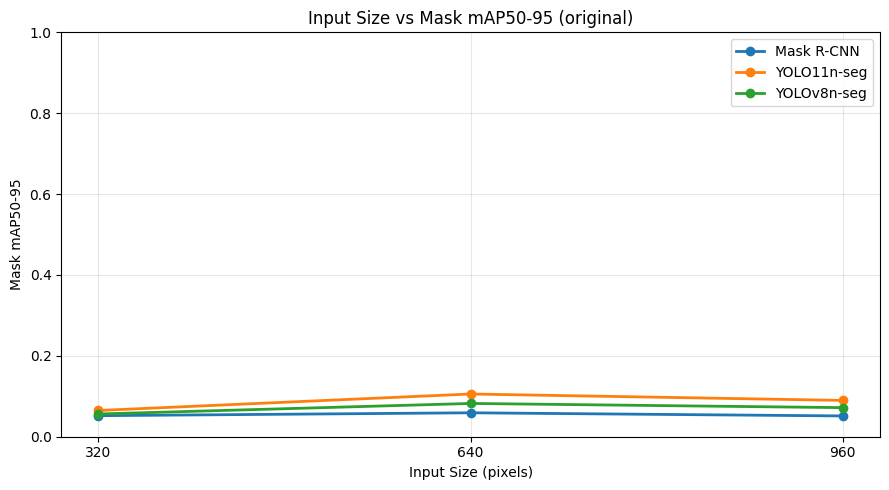

Grafik disimpan: /content/drive/MyDrive/CPMK3/evaluation/FINAL_RETEST40_input_size_original.png


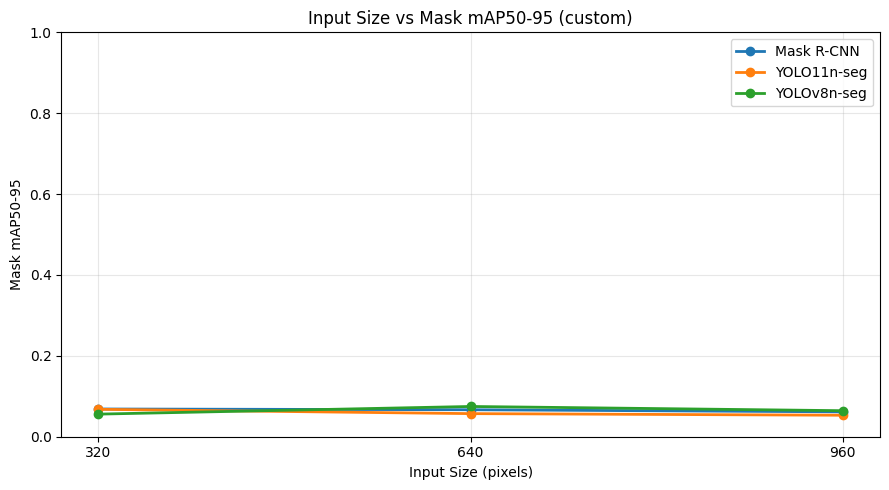

Grafik disimpan: /content/drive/MyDrive/CPMK3/evaluation/FINAL_RETEST40_input_size_custom.png


In [37]:
import matplotlib.pyplot as plt

for test_set in ["original", "custom"]:

    subset = df_final[
        df_final["test_set"] == test_set
    ]

    plt.figure(figsize=(9, 5))

    for model_name in subset["model"].unique():
        model_data = subset[
            subset["model"] == model_name
        ].sort_values("input_size")

        plt.plot(
            model_data["input_size"],
            model_data["mask_mAP50_95"],
            marker="o",
            linewidth=2,
            label=model_name
        )

    plt.title(
        f"Input Size vs Mask mAP50-95 ({test_set})"
    )
    plt.xlabel("Input Size (pixels)")
    plt.ylabel("Mask mAP50-95")
    plt.xticks([320, 640, 960])
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    save_path = (
        EVAL_DIR /
        f"FINAL_RETEST40_input_size_{test_set}.png"
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Grafik disimpan:", save_path)

terbaik

In [57]:
import pandas as pd
from pathlib import Path

# Baca hasil evaluasi final setelah RETEST40
file_path = Path(
    "/content/drive/MyDrive/CPMK3/evaluation/"
    "FINAL_RETEST40_all_results.csv"
)

df_final = pd.read_csv(file_path)

# Cari model terbaik pada setiap test set
for test_set in ["original", "custom"]:

    subset = df_final[
        df_final["test_set"] == test_set
    ]

    best = subset.loc[
        subset["mask_mAP50_95"].idxmax()
    ]

    print(f"\n=== TEST SET: {test_set.upper()} ===")
    print("Model:", best["model"])
    print("Input size:", best["input_size"])
    print("Mask mAP50:", round(best["mask_mAP50"], 4))
    print("Mask mAP50-95:", round(best["mask_mAP50_95"], 4))


=== TEST SET: ORIGINAL ===
Model: YOLO11n-seg
Input size: 640
Mask mAP50: 0.164
Mask mAP50-95: 0.1057

=== TEST SET: CUSTOM ===
Model: YOLOv8n-seg
Input size: 640
Mask mAP50: 0.1334
Mask mAP50-95: 0.0748


## Analisis Domain Shift

=== DOMAIN SHIFT (mAP50-95) ===


,model,input_size,custom,original,gap
0,Mask R-CNN,320,0.0686,0.0520,0.0165
1,Mask R-CNN,640,0.0667,0.0592,0.0076
2,Mask R-CNN,960,0.0615,0.0514,0.0101
3,YOLO11n-seg,320,0.0678,0.0649,0.0029
4,YOLO11n-seg,640,0.0571,0.1057,-0.0486
5,YOLO11n-seg,960,0.0531,0.0898,-0.0366
6,YOLOv8n-seg,320,0.0559,0.0562,-0.0003
7,YOLOv8n-seg,640,0.0748,0.0823,-0.0075
8,YOLOv8n-seg,960,0.0643,0.0719,-0.0076


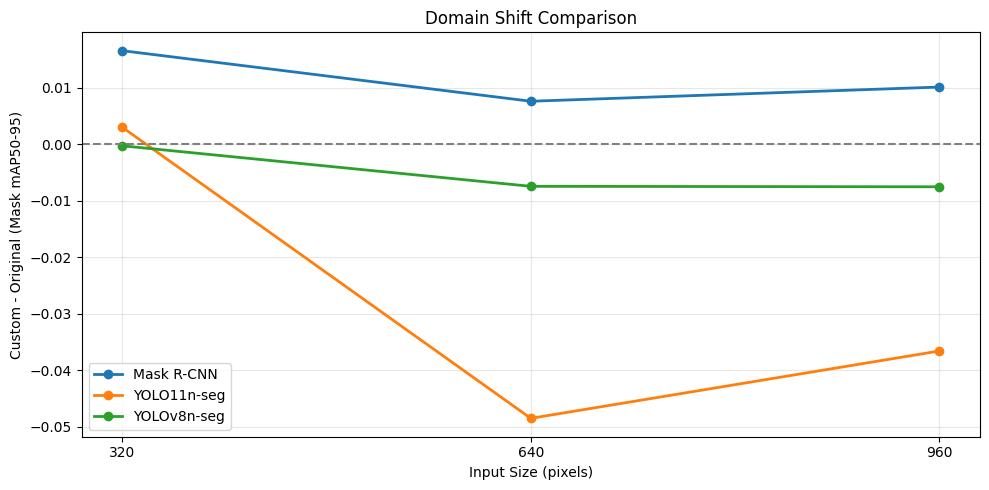

In [39]:
# Hitung gap mAP50-95
domain_shift = df_final.pivot(
    index=["model", "input_size"],
    columns="test_set",
    values="mask_mAP50_95"
).reset_index()

domain_shift.columns.name = None

domain_shift["gap"] = (
    domain_shift["custom"]
    - domain_shift["original"]
)

print("=== DOMAIN SHIFT (mAP50-95) ===")
display(domain_shift.round(4))

domain_shift.to_csv(
    EVAL_DIR / "FINAL_RETEST40_domain_shift.csv",
    index=False
)

# Grafik domain shift
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for model_name in domain_shift["model"].unique():

    subset = domain_shift[
        domain_shift["model"] == model_name
    ].sort_values("input_size")

    plt.plot(
        subset["input_size"],
        subset["gap"],
        marker="o",
        linewidth=2,
        label=model_name
    )

plt.axhline(0, linestyle="--", color="gray")
plt.xlabel("Input Size (pixels)")
plt.ylabel("Custom - Original (Mask mAP50-95)")
plt.title("Domain Shift Comparison")
plt.xticks([320, 640, 960])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    EVAL_DIR / "FINAL_RETEST40_domain_shift.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Analisis lima foto yang gagal

load model

In [40]:
import os
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Dataset custom dengan ID kelas yang sudah disesuaikan
image_dir = "/content/custom-yolo-samaid/test/images"
label_dir = "/content/custom-yolo-samaid/test/labels"

# Folder untuk menyimpan bukti analisis
failure_dir = (
    "/content/drive/MyDrive/CPMK3/"
    "failure_analysis"
)
os.makedirs(failure_dir, exist_ok=True)

# Model YOLO11n-seg hasil training
model_failure = YOLO(
    "/content/drive/MyDrive/CPMK3/results/"
    "YOLO11n_640/weights/best.pt"
)

image_files = sorted([
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

print("Jumlah gambar:", len(image_files))
print("Model berhasil dimuat!")

Jumlah gambar: 40
Model berhasil dimuat!


fungsi visualisasi

In [48]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import yaml

from pathlib import Path

with open(FAILURE_DATA / "data.yaml") as f:
    failure_config = yaml.safe_load(f)

class_names = failure_config["names"]

def get_class_name(class_id):
    if isinstance(class_names, dict):
        return class_names.get(
            class_id,
            class_names.get(str(class_id), str(class_id))
        )
    return class_names[class_id]

def make_failure_views(image_path, imgsz=640):
    image_path = Path(image_path)

    # Original
    bgr = cv2.imread(str(image_path))
    if bgr is None:
        raise ValueError(f"Gambar gagal dibaca: {image_path}")

    original = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    h, w = original.shape[:2]

    # Ground truth
    gt = original.copy()

    label_path = (
        FAILURE_LABELS / (image_path.stem + ".txt")
    )

    with open(label_path) as f:
        lines = f.readlines()

    rng = np.random.default_rng(42)

    for line in lines:
        values = line.strip().split()

        if not values:
            continue

        class_id = int(values[0])

        coords = np.array(
            [float(x) for x in values[1:]]
        ).reshape(-1, 2)

        coords[:, 0] *= w
        coords[:, 1] *= h

        polygon = coords.astype(np.int32)

        color = tuple(
            int(x) for x in rng.integers(40, 256, 3)
        )

        layer = gt.copy()
        cv2.fillPoly(layer, [polygon], color)

        gt = cv2.addWeighted(
            layer, 0.45, gt, 0.55, 0
        )

        x, y = polygon[0]
        cv2.putText(
            gt,
            get_class_name(class_id),
            (max(0, int(x)), max(15, int(y))),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 255, 255),
            2
        )

    # Prediction
    result = model_failure.predict(
        source=str(image_path),
        imgsz=imgsz,
        conf=0.25,
        verbose=False
    )[0]

    prediction = cv2.cvtColor(
        result.plot(),
        cv2.COLOR_BGR2RGB
    )

    return original, gt, prediction

print("Fungsi visualisasi berhasil dibuat!")

Fungsi visualisasi berhasil dibuat!


caari 5 foto


FOTO ASLI DARI ANOTASI-VISKOM-2
Lokasi: /content/anotasi-viskom-2/test
Jumlah gambar: 40


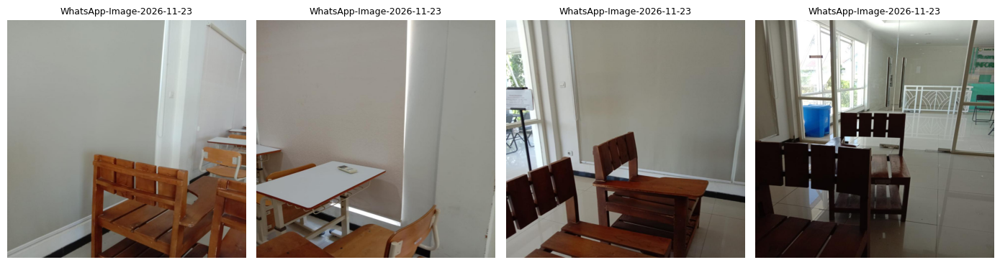


FOTO DARI CUSTOM-YOLO-SAMAID
Lokasi: /content/custom-yolo-samaid/test/images
Jumlah gambar: 40


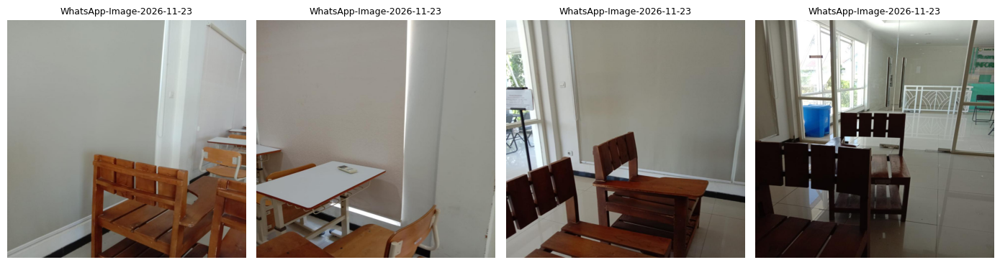

In [42]:

import os
import matplotlib.pyplot as plt
from PIL import Image

# Folder asli 40 fotomu
custom_coco_dir = "/content/anotasi-viskom-2/test"

# Folder hasil konversi YOLO
custom_yolo_dir = "/content/custom-yolo-samaid/test/images"

def show_samples(folder, title):
    if not os.path.exists(folder):
        print(f"Folder tidak ditemukan: {folder}")
        return

    images = sorted([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    print(f"\n{title}")
    print("Lokasi:", folder)
    print("Jumlah gambar:", len(images))

    if not images:
        return

    fig, axes = plt.subplots(
        1, min(4, len(images)),
        figsize=(14, 4)
    )

    if len(images[:4]) == 1:
        axes = [axes]

    for ax, filename in zip(axes, images[:4]):
        image = Image.open(
            os.path.join(folder, filename)
        )

        ax.imshow(image)
        ax.set_title(filename[:25], fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_samples(
    custom_coco_dir,
    "FOTO ASLI DARI ANOTASI-VISKOM-2"
)

show_samples(
    custom_yolo_dir,
    "FOTO DARI CUSTOM-YOLO-SAMAID"
)


In [44]:

from pathlib import Path
from ultralytics import YOLO

# Dataset 40 foto yang sudah diperbaiki
FAILURE_DATA = Path("/content/custom-yolo-samaid")

FAILURE_IMAGES = FAILURE_DATA / "test/images"
FAILURE_LABELS = FAILURE_DATA / "test/labels"

# Model hasil training
MODEL_PATH = Path(
    "/content/drive/MyDrive/CPMK3/results/"
    "YOLO11n_640/weights/best.pt"
)

assert FAILURE_IMAGES.is_dir(), "Folder gambar tidak ditemukan"
assert FAILURE_LABELS.is_dir(), "Folder label tidak ditemukan"
assert MODEL_PATH.is_file(), "Checkpoint model tidak ditemukan"

failure_files = sorted([
    p for p in FAILURE_IMAGES.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

assert len(failure_files) == 40, (
    f"STOP! Ditemukan {len(failure_files)} gambar, bukan 40."
)

assert all(
    (FAILURE_LABELS / (p.stem + ".txt")).is_file()
    for p in failure_files
), "Ada gambar yang tidak mempunyai file anotasi."

model_failure = YOLO(str(MODEL_PATH))

print("Jumlah foto:", len(failure_files))
print("Dataset:", FAILURE_IMAGES)
print("Model berhasil dimuat!")
print("VALIDASI BERHASIL")

Jumlah foto: 40
Dataset: /content/custom-yolo-samaid/test/images
Model berhasil dimuat!
VALIDASI BERHASIL


Foto 1: WhatsApp-Image-2026-11-23-at-13-33-04_jpeg.rf.6e10e0c86bbe48144b74f297d2490c2a.jpg
Foto 2: WhatsApp-Image-2026-11-23-at-13-33-05-1-_jpeg.rf.79f07dd40272c884d64d5243da10839b.jpg
Foto 3: WhatsApp-Image-2026-11-23-at-13-33-05_jpeg.rf.5a36804dd32a6fd1a52fb21e506064cd.jpg
Foto 4: WhatsApp-Image-2026-11-23-at-13-33-06-1-_jpeg.rf.774f015ba7c96451303fca199590ec79.jpg


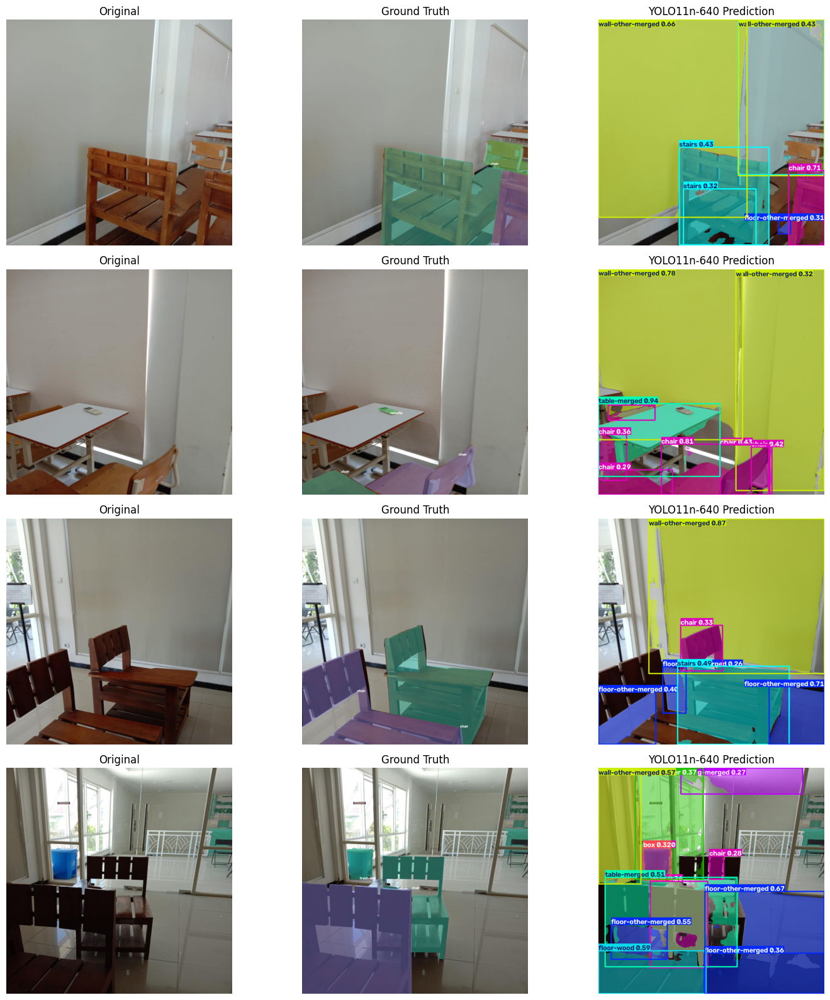

Foto 5: WhatsApp-Image-2026-11-23-at-13-33-06-2-_jpeg.rf.13bcf98fdf9b65f0308d8d11f72a851c.jpg
Foto 6: WhatsApp-Image-2026-11-23-at-13-33-06_jpeg.rf.4c20ae68a30bdec1a958a2eb3e4b5365.jpg
Foto 7: WhatsApp-Image-2026-11-23-at-13-33-07-1-_jpeg.rf.105e6fc5f6deec218c11d35d84bd6915.jpg
Foto 8: WhatsApp-Image-2026-11-23-at-13-33-07-3-_jpeg.rf.28d5c166cee1fb841d790b775f23772f.jpg


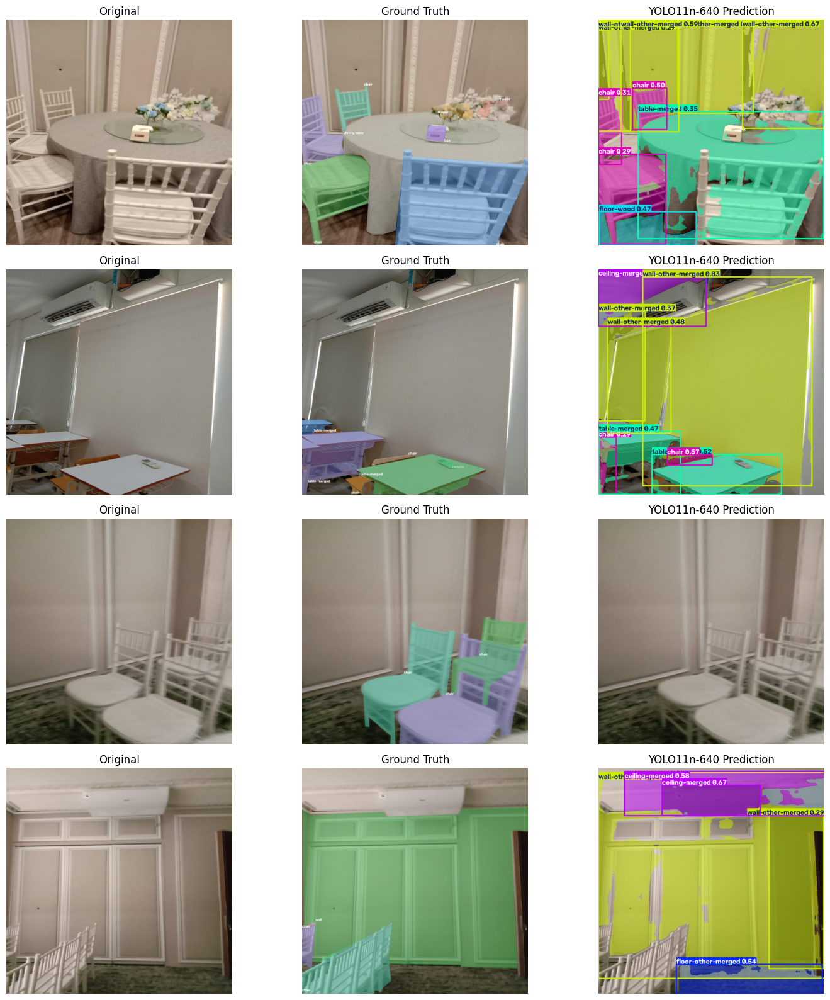

Foto 9: WhatsApp-Image-2026-11-23-at-13-33-07_jpeg.rf.9731b004a4e9d552117e78e04ee9dca6.jpg
Foto 10: WhatsApp-Image-2026-11-23-at-13-33-09_jpeg.rf.6eb6d383102783b0a162d94b8e647ea2.jpg
Foto 11: WhatsApp-Image-2026-11-24-at-13-03-39_jpeg.rf.a469a2de9f9a746f339a1e0c0f91a72a.jpg
Foto 12: WhatsApp-Image-2026-11-24-at-13-03-40-1-_jpeg.rf.aa621fe422b392e6c5ecc255f0ade770.jpg


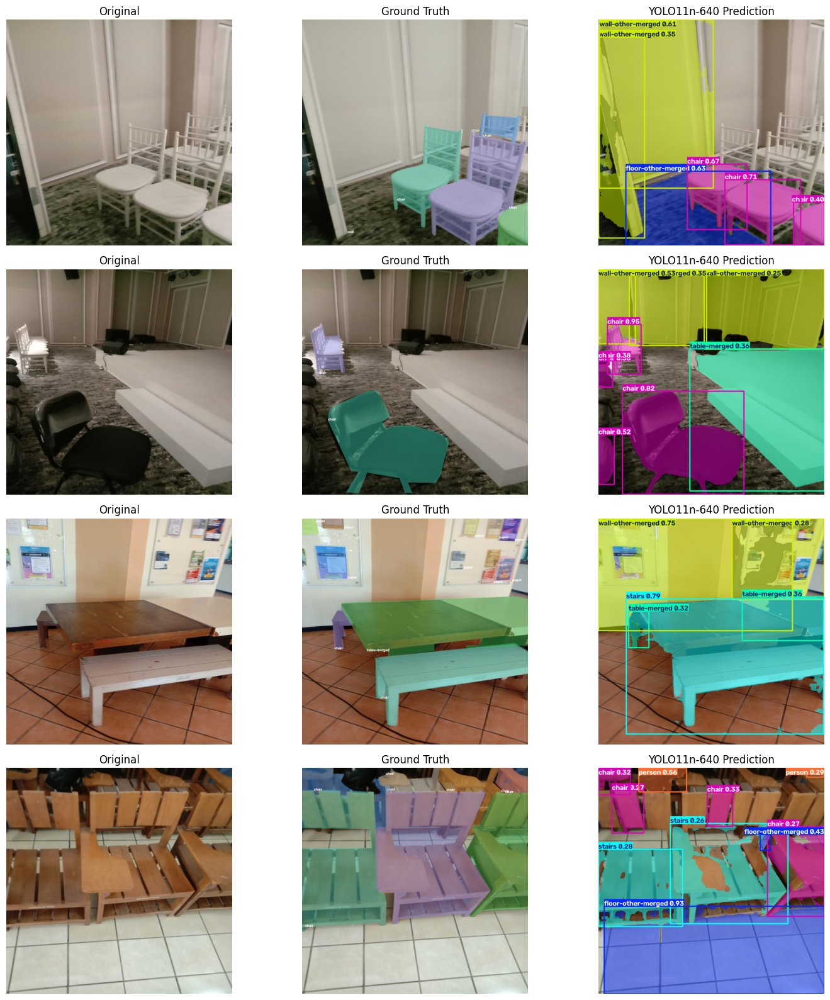

Foto 13: WhatsApp-Image-2026-11-24-at-13-03-40-2-_jpeg.rf.266f0fa0580666eba39e810bec493689.jpg
Foto 14: WhatsApp-Image-2026-11-24-at-13-03-40_jpeg.rf.d94dddf36ffe3e20571abe200a804ccb.jpg
Foto 15: WhatsApp-Image-2026-11-24-at-13-03-41_jpeg.rf.5e46942eabfcdfc4601e17e850980884.jpg
Foto 16: WhatsApp-Image-2026-11-24-at-13-03-42_jpeg.rf.ea46bc217676b993f3e250ebe9a2d971.jpg


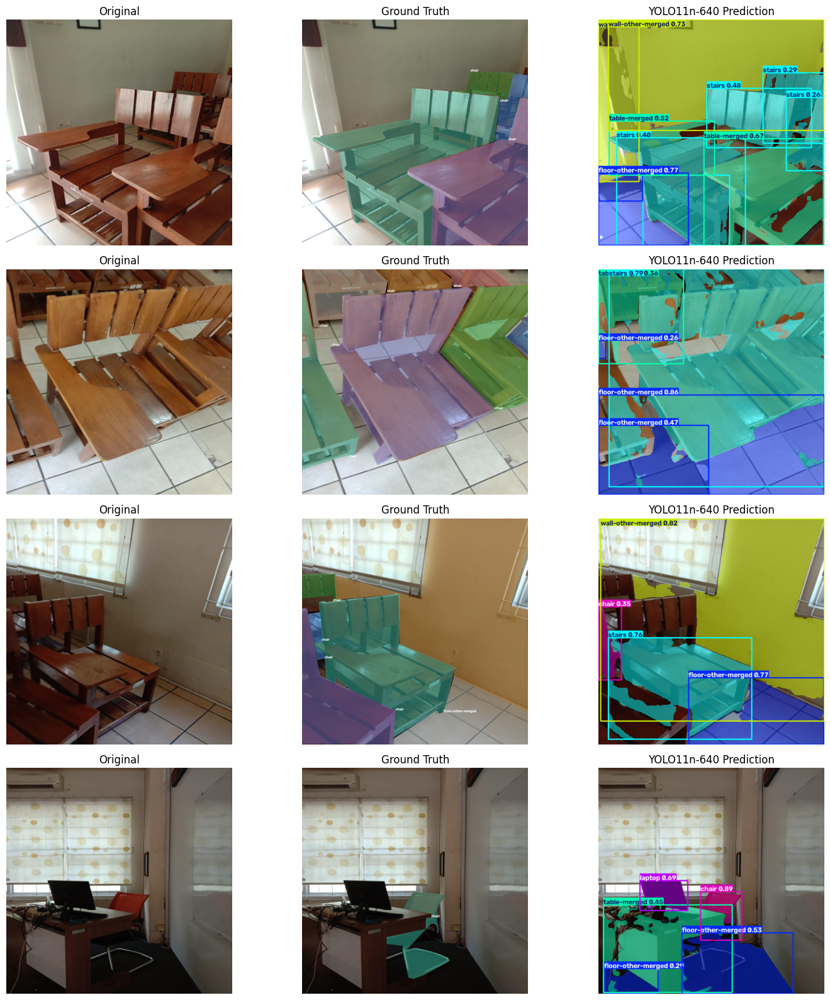

Foto 17: WhatsApp-Image-2026-11-24-at-13-03-43-1-_jpeg.rf.987fb4569f09fa6dda0e775d9ff7aa6b.jpg
Foto 18: WhatsApp-Image-2026-11-24-at-13-03-43-2-_jpeg.rf.f777c178c94fad44cc20bb9a83ce709a.jpg
Foto 19: WhatsApp-Image-2026-11-24-at-13-03-43_jpeg.rf.bbe35ab564dd0f4b6dab999dbd899a57.jpg
Foto 20: WhatsApp-Image-2026-11-24-at-13-03-44-1-_jpeg.rf.264659b91d199ce65fb7535ac259e7c5.jpg


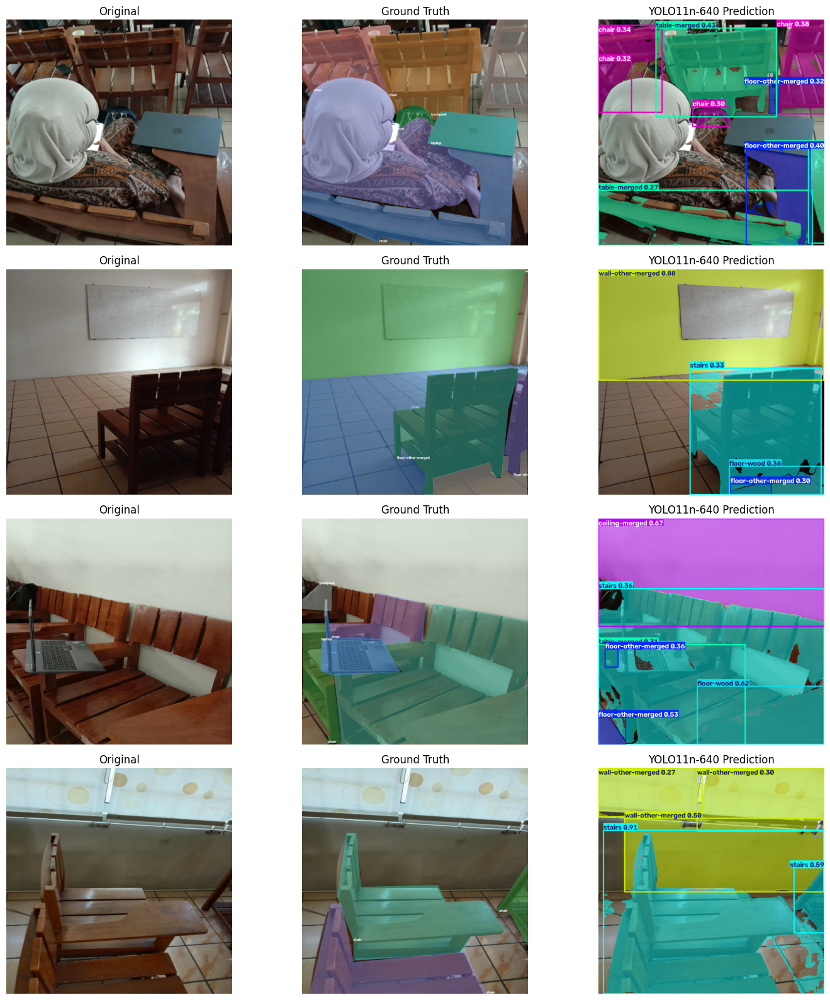

Foto 21: WhatsApp-Image-2026-11-24-at-13-03-44-2-_jpeg.rf.13e64cdafbeb43091a533a7cecc5e9ac.jpg
Foto 22: WhatsApp-Image-2026-11-24-at-13-03-44_jpeg.rf.4354f6248fad5f8f8725c39cf3a3f03d.jpg
Foto 23: WhatsApp-Image-2026-11-24-at-13-03-45-2-_jpeg.rf.859c1d4b39424193bc0844a57c9abb64.jpg
Foto 24: WhatsApp-Image-2026-11-24-at-13-03-45-3-_jpeg.rf.195690cc9b49f8f47441813cf5cd3e48.jpg


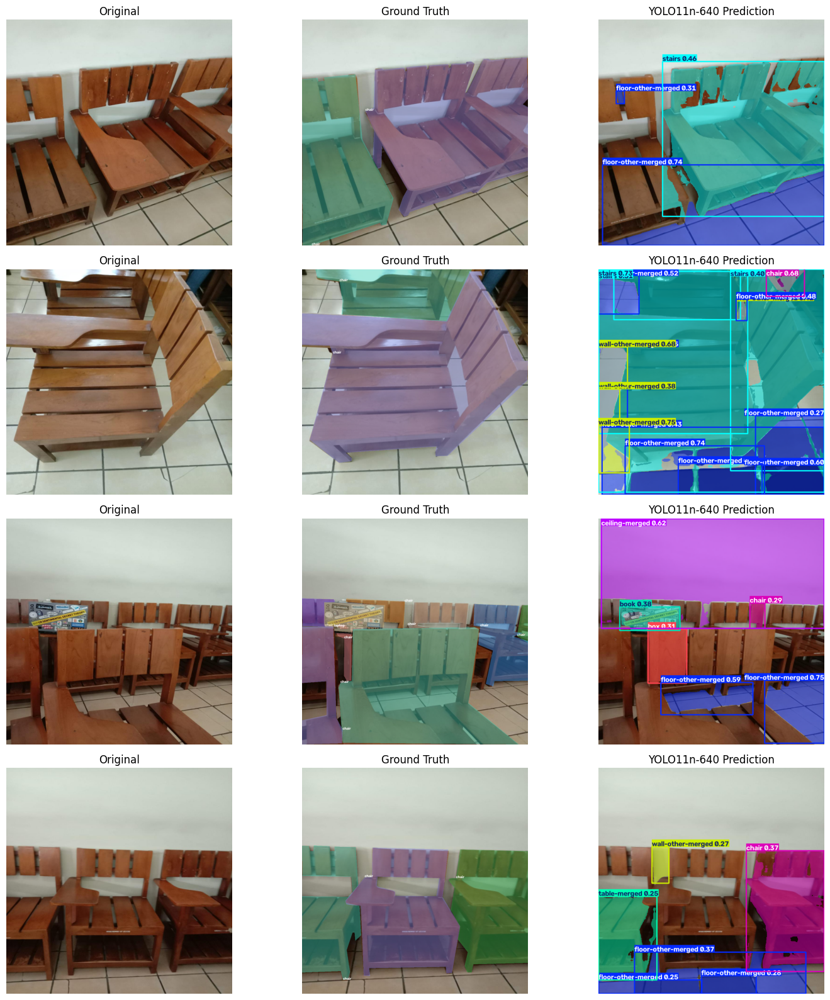

Foto 25: WhatsApp-Image-2026-11-24-at-13-03-45_jpeg.rf.11ff605d7a4f01760d0acf3a150694f3.jpg
Foto 26: WhatsApp-Image-2026-11-24-at-13-03-46-1-_jpeg.rf.8d5ee283b0f3fd8c21636c266fb940a5.jpg
Foto 27: WhatsApp-Image-2026-11-24-at-13-03-46-2-_jpeg.rf.e129db54e9528dba119a92964040a1e7.jpg
Foto 28: WhatsApp-Image-2026-11-24-at-13-03-46_jpeg.rf.9cf2da49dab432b77f3b26e69231171a.jpg


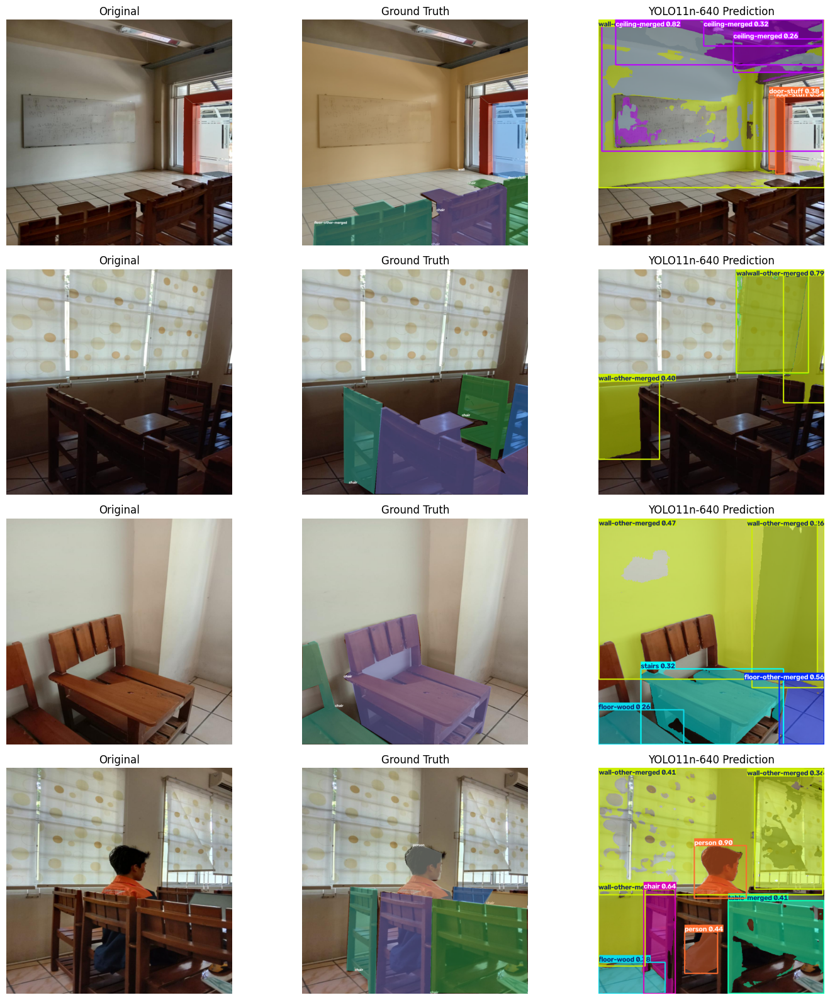

Foto 29: WhatsApp-Image-2026-11-24-at-17-08-19_jpeg.rf.28578ca285d2382152da319b1e686f90.jpg
Foto 30: WhatsApp-Image-2026-11-24-at-17-09-44_jpeg.rf.9eecafe85fb1b55537f68ca1595ca824.jpg
Foto 31: WhatsApp-Image-2026-11-24-at-17-09-45_jpeg.rf.0981a519e5fa3631c50dd4780652a3c7.jpg
Foto 32: WhatsApp-Image-2026-11-24-at-17-46-14_jpeg.rf.7261f2de6d22388d70b4040a29adb678.jpg


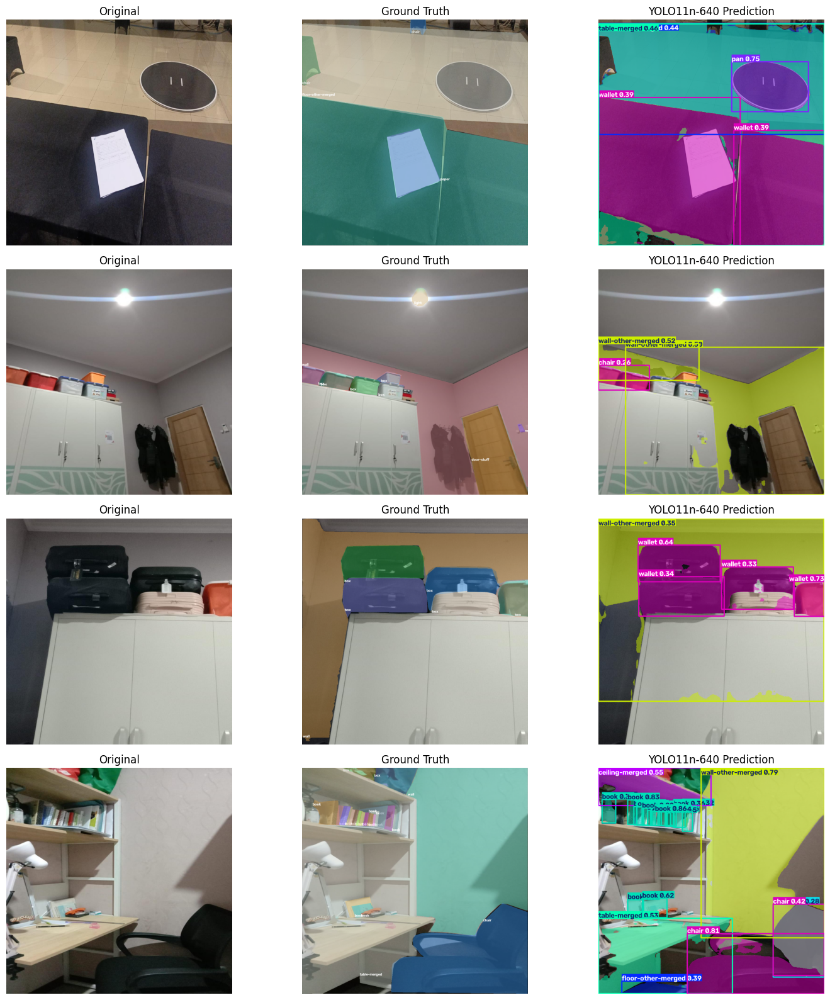

Foto 33: WhatsApp-Image-2026-11-24-at-17-46-15-1-_jpeg.rf.118021bc545268d42b601e67a33468d7.jpg
Foto 34: WhatsApp-Image-2026-11-24-at-17-46-15-2-_jpeg.rf.362ba1a968aaecfb93c28d752be3316b.jpg
Foto 35: WhatsApp-Image-2026-11-24-at-17-46-15_jpeg.rf.5442e7d866e16aa0b00de5c7cfe988ec.jpg
Foto 36: WhatsApp-Image-2026-11-24-at-17-46-16-1-_jpeg.rf.65fe55ae9e83987cb7ae2e3ab0469713.jpg


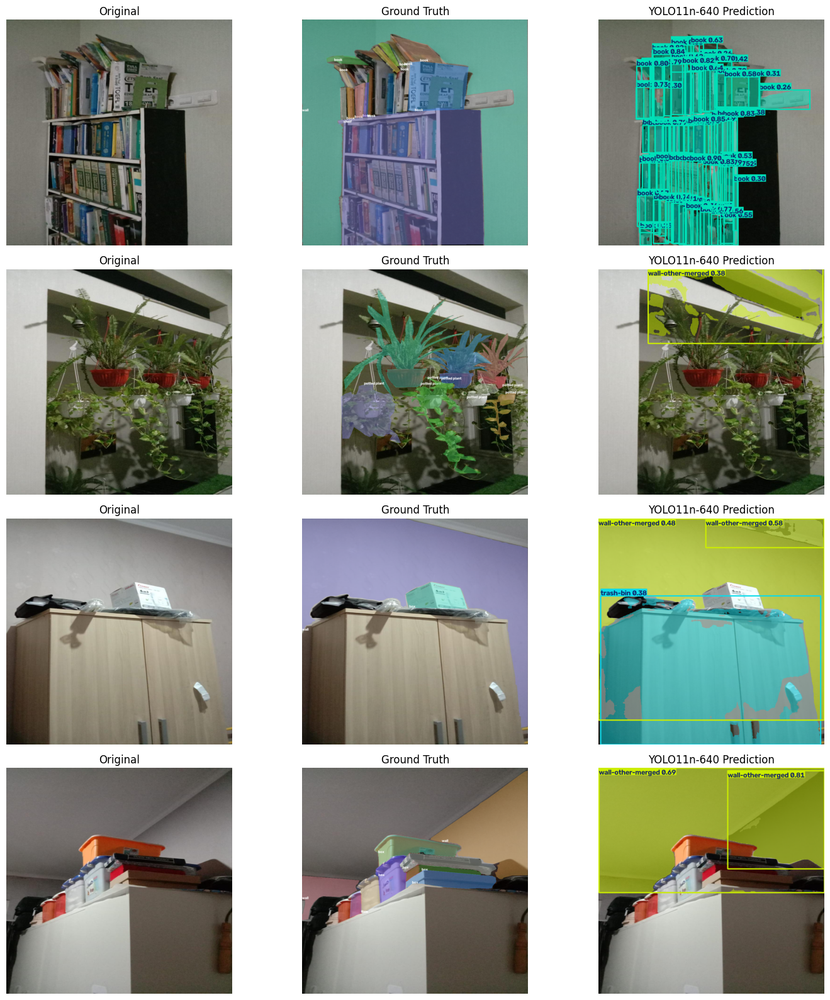

Foto 37: WhatsApp-Image-2026-11-24-at-17-46-16-2-_jpeg.rf.b7172a24904b8326775fe990a2e8515b.jpg
Foto 38: WhatsApp-Image-2026-11-24-at-17-46-16_jpeg.rf.963c94b992e7aa08f135773aee0cb091.jpg
Foto 39: WhatsApp-Image-2026-11-24-at-17-46-17-1-_jpeg.rf.27323df315c079237deb0f8cca8def58.jpg
Foto 40: WhatsApp-Image-2026-11-24-at-17-46-17_jpeg.rf.54d9d666708160f9fb69a8c946186fa1.jpg


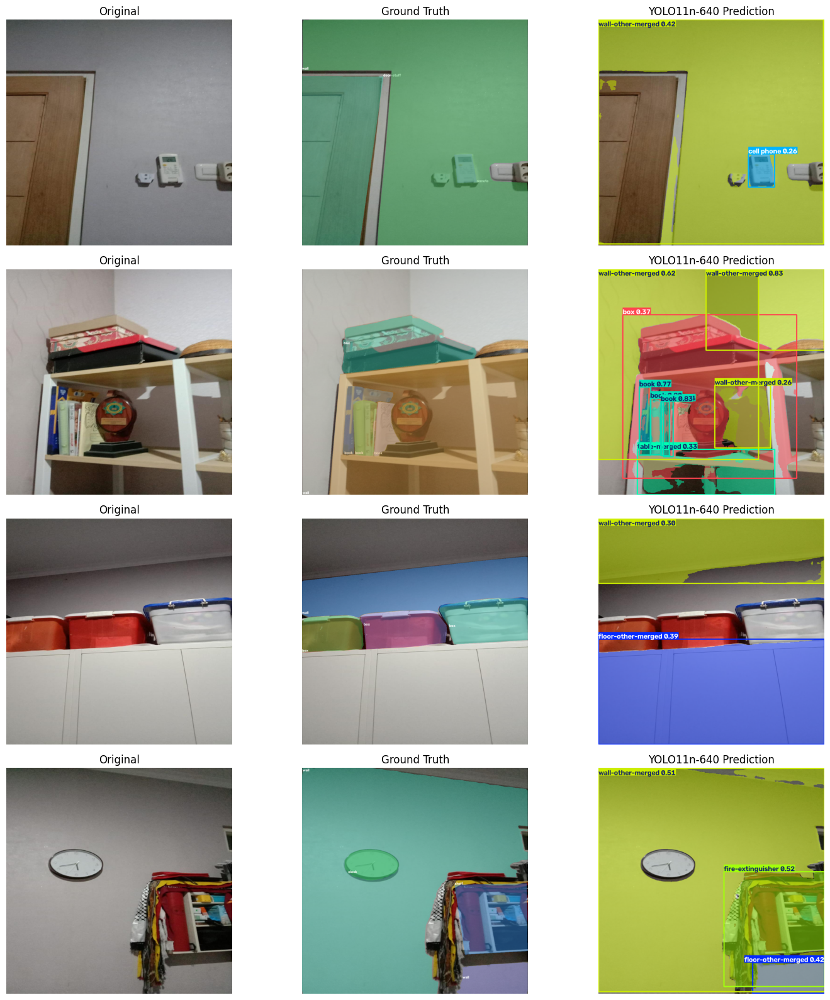


Semua 40 foto selesai divisualisasikan!
Hasil tersimpan di: /content/drive/MyDrive/CPMK3/failure_analysis/RETEST40


In [49]:
from pathlib import Path
import matplotlib.pyplot as plt

# Folder bukti analisis
FAILURE_OUTPUT = Path(
    "/content/drive/MyDrive/CPMK3/"
    "failure_analysis/RETEST40"
)

FAILURE_OUTPUT.mkdir(
    parents=True,
    exist_ok=True
)

# Simpan indeks nama foto
index_file = FAILURE_OUTPUT / "photo_index.txt"

with open(index_file, "w") as f:
    for i, path in enumerate(failure_files, 1):
        f.write(f"{i:02d}: {path.name}\n")

# Tampilkan 4 foto per halaman
for start in range(0, 40, 4):

    batch = failure_files[start:start+4]

    fig, axes = plt.subplots(
        len(batch), 3,
        figsize=(15, 4 * len(batch)),
        squeeze=False
    )

    for row, image_path in enumerate(batch):
        original, gt, prediction = make_failure_views(
            image_path, imgsz=640
        )

        views = [original, gt, prediction]
        titles = [
            "Original",
            "Ground Truth",
            "YOLO11n-640 Prediction"
        ]

        photo_number = start + row + 1

        for col in range(3):
            axes[row, col].imshow(views[col])
            axes[row, col].axis("off")
            axes[row, col].set_title(titles[col])

        axes[row, 0].set_ylabel(
            f"Foto {photo_number}",
            fontsize=12
        )

        print(
            f"Foto {photo_number}:",
            image_path.name
        )

    plt.tight_layout()

    page = start // 4 + 1

    save_path = (
        FAILURE_OUTPUT /
        f"failure_review_page_{page:02d}.png"
    )

    plt.savefig(
        save_path,
        dpi=140,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("\nSemua 40 foto selesai divisualisasikan!")
print("Hasil tersimpan di:", FAILURE_OUTPUT)

pilih 5

In [50]:
selected_numbers = [7, 29, 34, 37, 39]

assert len(selected_numbers) == 5
assert len(set(selected_numbers)) == 5
assert all(1 <= n <= 40 for n in selected_numbers)

selected_failures = [
    failure_files[n - 1]
    for n in selected_numbers
]

for n, path in zip(
    selected_numbers, selected_failures
):
    print(f"Foto {n}: {path.name}")

Foto 7: WhatsApp-Image-2026-11-23-at-13-33-07-1-_jpeg.rf.105e6fc5f6deec218c11d35d84bd6915.jpg
Foto 29: WhatsApp-Image-2026-11-24-at-17-08-19_jpeg.rf.28578ca285d2382152da319b1e686f90.jpg
Foto 34: WhatsApp-Image-2026-11-24-at-17-46-15-2-_jpeg.rf.362ba1a968aaecfb93c28d752be3316b.jpg
Foto 37: WhatsApp-Image-2026-11-24-at-17-46-16-2-_jpeg.rf.b7172a24904b8326775fe990a2e8515b.jpg
Foto 39: WhatsApp-Image-2026-11-24-at-17-46-17-1-_jpeg.rf.27323df315c079237deb0f8cca8def58.jpg


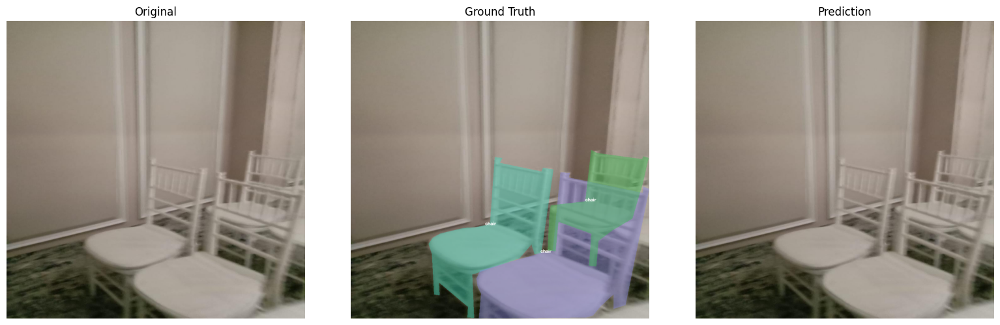

Disimpan: /content/drive/MyDrive/CPMK3/failure_analysis/RETEST40/FAILURE_07.png


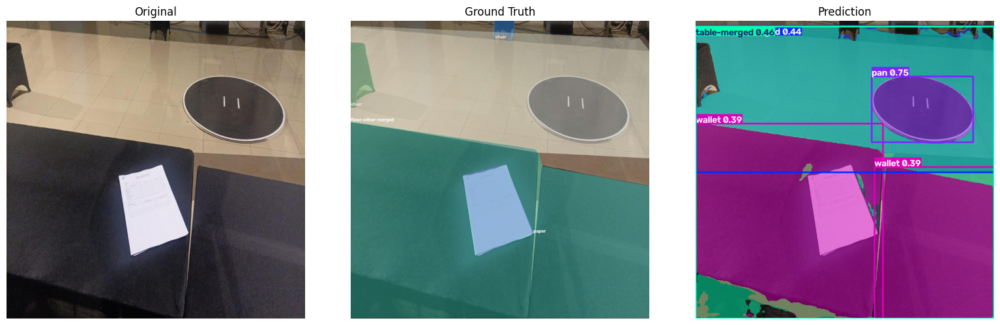

Disimpan: /content/drive/MyDrive/CPMK3/failure_analysis/RETEST40/FAILURE_29.png


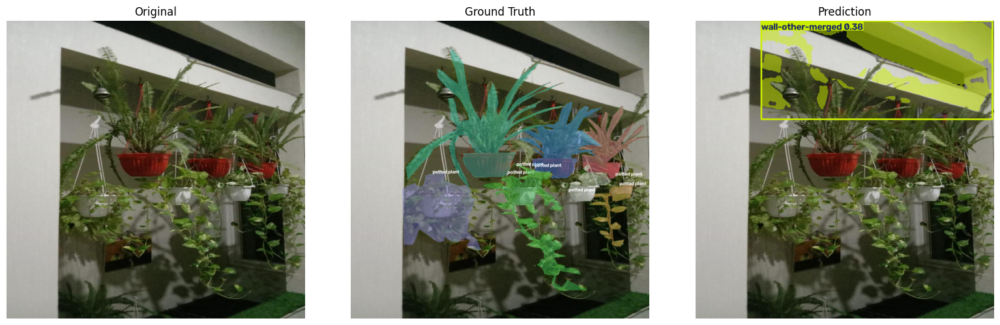

Disimpan: /content/drive/MyDrive/CPMK3/failure_analysis/RETEST40/FAILURE_34.png


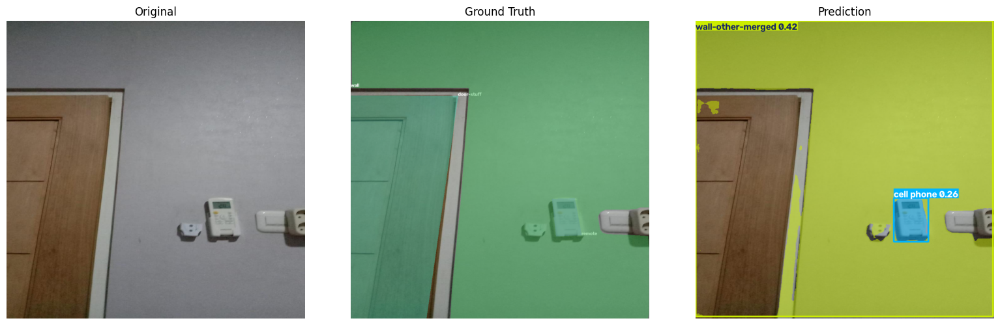

Disimpan: /content/drive/MyDrive/CPMK3/failure_analysis/RETEST40/FAILURE_37.png


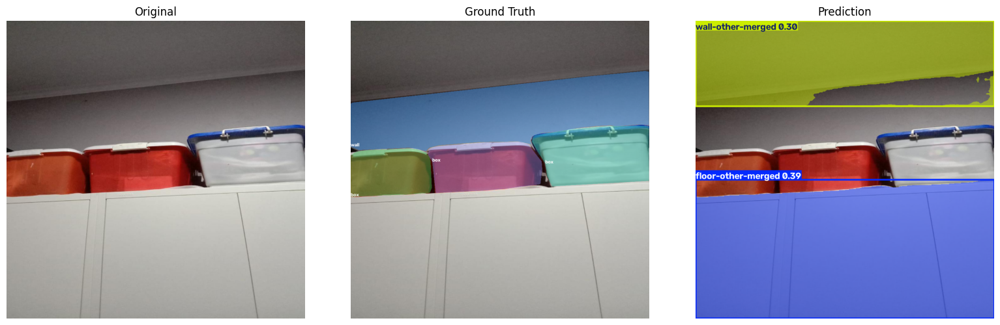

Disimpan: /content/drive/MyDrive/CPMK3/failure_analysis/RETEST40/FAILURE_39.png


In [51]:
for number, path in zip(
    selected_numbers, selected_failures
):
    original, gt, prediction = make_failure_views(
        path, imgsz=640
    )

    fig, axes = plt.subplots(
        1, 3, figsize=(16, 5)
    )

    for ax, img, title in zip(
        axes,
        [original, gt, prediction],
        ["Original", "Ground Truth", "Prediction"]
    ):
        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()

    save_path = (
        FAILURE_OUTPUT /
        f"FAILURE_{number:02d}.png"
    )

    plt.savefig(
        save_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print("Disimpan:", save_path)

## Eksperimen Kecil untuk Membuktikan Penyebab Kegagalan Model

pilih foto

In [58]:
from pathlib import Path

FAILURE_IMAGES = Path(
    "/content/custom-yolo-samaid/test/images"
)

failure_files = sorted([
    p for p in FAILURE_IMAGES.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

assert len(failure_files) == 40, (
    f"Dataset salah! Ditemukan {len(failure_files)} foto."
)

# Foto nomor 37 dari daftar 40 foto
REMOTE_PATH = failure_files[36]

assert REMOTE_PATH.is_file()

print("Foto asli yang digunakan:", REMOTE_PATH.name)
print("Lokasi:", REMOTE_PATH)

Foto asli yang digunakan: WhatsApp-Image-2026-11-24-at-17-46-16-2-_jpeg.rf.b7172a24904b8326775fe990a2e8515b.jpg
Lokasi: /content/custom-yolo-samaid/test/images/WhatsApp-Image-2026-11-24-at-17-46-16-2-_jpeg.rf.b7172a24904b8326775fe990a2e8515b.jpg


predikssi dengn 3 ukuran input

In [59]:

from ultralytics import YOLO
import pandas as pd

MODEL_PATH = (
    "/content/drive/MyDrive/CPMK3/results/"
    "YOLO11n_640/weights/best.pt"
)

model = YOLO(MODEL_PATH)

sizes = [320, 640, 960]
experiment_results = {}
rows = []

for size in sizes:
    result = model.predict(
        source=str(REMOTE_PATH),
        imgsz=size,
        conf=0.25,
        verbose=False
    )[0]

    experiment_results[size] = result

    print(f"\n=== INFERENCE SIZE {size} ===")

    if len(result.boxes) == 0:
        print("Tidak ada objek terdeteksi")

    for box in result.boxes:
        class_id = int(box.cls.item())
        confidence = float(box.conf.item())
        class_name = result.names[class_id]

        print(f"{class_name}: {confidence:.3f}")

        rows.append({
            "inference_size": size,
            "predicted_class": class_name,
            "confidence": confidence
        })

df_experiment = pd.DataFrame(
    rows,
    columns=[
        "inference_size",
        "predicted_class",
        "confidence"
    ]
)

display(df_experiment)


=== INFERENCE SIZE 320 ===
wall-other-merged: 0.667
plug: 0.301
plug: 0.254

=== INFERENCE SIZE 640 ===
wall-other-merged: 0.420
cell phone: 0.263

=== INFERENCE SIZE 960 ===
plug: 0.690


,inference_size,predicted_class,confidence
0,320,wall-other-merged,0.667182
1,320,plug,0.301158
2,320,plug,0.254422
3,640,wall-other-merged,0.420166
4,640,cell phone,0.262791
5,960,plug,0.689980


perbandngan visual

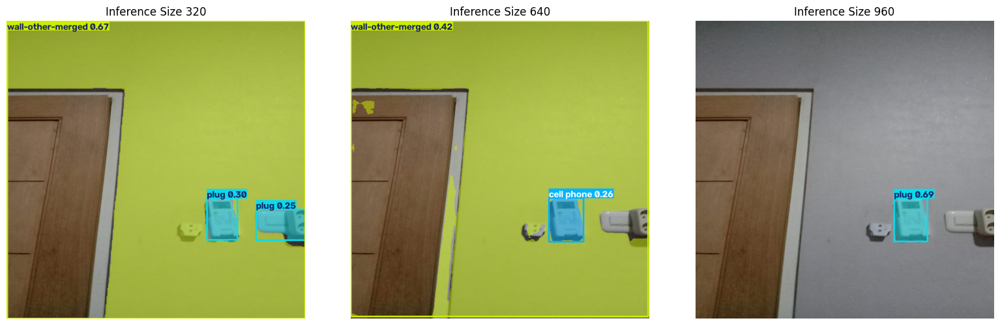

Hasil tersimpan di: /content/drive/MyDrive/CPMK3/failure_analysis/experiment_remote_corrected


In [60]:
import matplotlib.pyplot as plt
import cv2
from pathlib import Path

EXPERIMENT_DIR = Path(
    "/content/drive/MyDrive/CPMK3/"
    "failure_analysis/experiment_remote_corrected"
)

EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, size in zip(axes, sizes):
    result = experiment_results[size]

    prediction = cv2.cvtColor(
        result.plot(),
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(prediction)
    ax.set_title(f"Inference Size {size}")
    ax.axis("off")

plt.tight_layout()

fig.savefig(
    EXPERIMENT_DIR / "remote_comparison_corrected.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# Simpan hasil CSV baru
df_experiment.to_csv(
    EXPERIMENT_DIR / "remote_results_corrected.csv",
    index=False
)

print("Hasil tersimpan di:", EXPERIMENT_DIR)